### Meta model (with penalties)

In [ ]:
import numpy as np
import pandas as pd
import spacy
from textstat import textstat
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sentence_transformers import SentenceTransformer
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from xgboost import XGBRegressor
from keras.models import Sequential
from keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from keras.optimizers import Adam
from spellchecker import SpellChecker
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load NLP Models
nlp = spacy.load('en_core_web_sm')
sentiment_analyzer = SentimentIntensityAnalyzer()
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')
spell = SpellChecker()


def calculate_feature_penalties(features):
    penalties = {}

    PENALTY_FEATURES = {
        "word_count": {"range": (200, 300), "max_penalty": 3.0, "exponential_factor": 3.0},
        "flesch_kincaid": {"range": (8, 20), "max_penalty": 3.0, "exponential_factor": 2.0},
        "topic_relevance": {"range": (0.3, 1.0), "max_penalty": 2.0, "exponential_factor": 4.0},
        "misspelled_ratio": {"range": (0, 0.05), "max_penalty": 2.0, "exponential_factor": 5.0},
    }

    total_penalty = 0.0

    for feature, config in PENALTY_FEATURES.items():
        value = features.get(feature, 0)  # Ensure feature exists
        min_val, max_val = config["range"]
        max_penalty = config["max_penalty"]
        exp_factor = config["exponential_factor"]

        deviation = max(0, (min_val - value) / min_val if value < min_val else (value - max_val) / max_val)

        if deviation > 0:
            penalty = max_penalty * (1 - np.exp(-exp_factor * deviation))
            penalty = min(penalty, max_penalty)  # Cap at max penalty

            penalties[feature] = {
                "value": value,
                "deviation": deviation,
                "penalty": penalty,
                "reason": f"{'Below' if value < min_val else 'Above'} expected range ({min_val}, {max_val})"
            }
            total_penalty += penalty
        else:
            penalties[feature] = {"value": value, "deviation": 0, "penalty": 0, "reason": "Within expected range"}

    return {"individual_penalties": penalties, "total_penalty": min(total_penalty, 10.0)}


def extract_features(essay, topic):
    doc = nlp(essay)
    words = [token.text for token in doc if token.is_alpha]
    word_count = len(words)
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(word.lower() for word in words))
    lexical_density = unique_words / word_count if word_count > 0 else 0
    ttr = unique_words / word_count if word_count > 0 else 0

    pos_count = {
        'NOUN': sum(1 for token in doc if token.pos_ == 'NOUN'),
        'VERB': sum(1 for token in doc if token.pos_ == 'VERB')
    }

    flesch_kincaid = textstat.flesch_kincaid_grade(essay)
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )
    
    # Spell check
    # Extract all words that aren't proper nouns, names, or special terminology
    word_tokens = [token.text.lower() for token in doc if token.is_alpha and not token.is_stop and not token.is_punct and not token.is_space and not token.is_digit and not token.pos_ == 'PROPN']
    
    # Find misspelled words
    misspelled = spell.unknown(word_tokens)
    misspelled_count = len(misspelled)
    misspelled_ratio = misspelled_count / word_count if word_count > 0 else 0
    
    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance,
        'misspelled_count': misspelled_count,
        'misspelled_ratio': misspelled_ratio,  # Make sure this feature is included
    }

    return features

# ✅ Load Data
df = pd.read_csv('essays.csv')
texts = df['Essay Answer']
scores = df['Score']
topics = df['Essay Question']

# Extract Features
print("Extracting features for all essays...")
features_list = [extract_features(essay, topic) for essay, topic in zip(texts, topics)]

# Create DataFrame with consistent columns
feature_columns = list(features_list[0].keys())  # Get all feature keys from the first entry
features_df = pd.DataFrame(features_list)

# Debug information
print(f"Features extracted: {feature_columns}")
print(f"Features dataframe shape: {features_df.shape}")

X_engineered = features_df
y = scores

tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(texts)
X_text = tokenizer.texts_to_sequences(texts)
X_text = pad_sequences(X_text, maxlen=500)

# Split into train, validation, and test sets
X_engineered_train, X_engineered_temp, X_text_train, X_text_temp, y_train, y_temp, topics_train, topics_temp, texts_train, texts_temp = train_test_split(
    X_engineered, X_text, y, topics, texts, test_size=0.3, random_state=42
)

# Further split temp into validation and test
X_engineered_val, X_engineered_test, X_text_val, X_text_test, y_val, y_test, topics_val, topics_test, texts_val, texts_test = train_test_split(
    X_engineered_temp, X_text_temp, y_temp, topics_temp, texts_temp, test_size=0.5, random_state=42
)

# ✅ Train Base Models
print("Training SVM model...")
# Save the column order during training to ensure consistency
train_columns = X_engineered_train.columns.tolist()
print(f"Training with columns: {train_columns}")

svm_model = SVR(C=10, epsilon=0.1, gamma='scale', kernel='rbf')
svm_model.fit(X_engineered_train, y_train)

print("Training RNN model...")
rnn_model = Sequential([
    Embedding(input_dim=5000, output_dim=128, input_length=500),
    Bidirectional(LSTM(128, return_sequences=False, kernel_regularizer="l2")),
    Dropout(0.5),
    Dense(64, activation='gelu', kernel_regularizer="l2"),
    Dropout(0.5),
    Dense(1)
])
rnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='mae', metrics=['mae'])
rnn_model.fit(X_text_train, y_train, batch_size=32, epochs=15, validation_data=(X_text_val, y_val), verbose=1)

# ✅ Generate predictions for meta-model training
print("Generating predictions for meta-model training...")
rnn_val_pred = rnn_model.predict(X_text_val).flatten()
svm_val_pred = svm_model.predict(X_engineered_val)
stacked_X_val = np.vstack((svm_val_pred, rnn_val_pred)).T

# ✅ Train meta-model on validation set predictions
print("Training meta-model...")
meta_model = XGBRegressor(n_estimators=500, max_depth=6, learning_rate=0.01, objective='reg:squarederror', random_state=42)
meta_model.fit(stacked_X_val, y_val)

# ✅ Score Prediction & Penalties for all test data
print("Calculating scores and penalties for all test data...")
results = []

for i in range(len(X_engineered_test)):
    # Get the current test sample
    essay = texts_test.iloc[i]
    topic = topics_test.iloc[i]
    actual_score = y_test.iloc[i]
    
    # Extract features
    features = extract_features(essay, topic)
    
    # Ensure features are in the same order as during training
    feature_vector = pd.Series(features).reindex(train_columns).values.reshape(1, -1)
    
    # Make predictions with base models
    engineered_score = svm_model.predict(feature_vector)[0]
    text_score = rnn_model.predict(X_text_test[i:i+1]).flatten()[0]
    
    # Make meta-model prediction
    stacked_inputs = np.array([engineered_score, text_score]).reshape(1, -1)
    predicted_score = meta_model.predict(stacked_inputs)[0]
    
    # Calculate penalties
    penalties = calculate_feature_penalties(features)
    total_penalty = penalties["total_penalty"]
    adjusted_score = max(0, predicted_score - total_penalty)
    
    # Calculate absolute difference
    abs_diff = abs(adjusted_score - actual_score)
    
    # Create result dictionary
    result = {
        'Essay Question': topic,
        'Essay Answer': essay,
        'Actual Score': actual_score,
        'Predicted Score': predicted_score,
        'Total Penalty': total_penalty,
        'Final Adjusted Score': adjusted_score,
        'Absolute Difference': abs_diff
    }
    
    # Add individual penalties
    for feature, penalty_info in penalties["individual_penalties"].items():
        result[f'{feature}_penalty'] = penalty_info["penalty"]
        result[f'{feature}_value'] = penalty_info["value"]
        result[f'{feature}_reason'] = penalty_info["reason"]
    
    # Add all features
    for feature, value in features.items():
        result[feature] = value
    
    results.append(result)
    
    # Print progress
    if (i+1) % 10 == 0:
        print(f"Processed {i+1}/{len(X_engineered_test)} test samples")

# Create DataFrame and save to CSV
results_df = pd.DataFrame(results)
results_df.to_csv("/Users/shivam/Downloads/final_scoring_results_with_spell_check.csv", index=False)

print("Results saved successfully!")

# Extract actual and predicted scores from the results
actual_scores = results_df['Actual Score'].values
final_adjusted_scores = results_df['Final Adjusted Score'].values

# Calculate MAE and RMSE
test_mae = mean_absolute_error(actual_scores, final_adjusted_scores)
test_rmse = np.sqrt(mean_squared_error(actual_scores, final_adjusted_scores))

# Print MAE and RMSE
print(f"Test MAE: {test_mae:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")

# Print summary statistics
mean_abs_diff = results_df['Absolute Difference'].mean()
median_abs_diff = results_df['Absolute Difference'].median()
print(f"Mean Absolute Difference: {mean_abs_diff:.2f}")
print(f"Median Absolute Difference: {median_abs_diff:.2f}")

# Print spelling statistics
avg_misspelled = results_df['misspelled_count'].mean()
print(f"Average misspelled words per essay: {avg_misspelled:.2f}")
print(f"Total essays with spelling errors: {(results_df['misspelled_count'] > 0).sum()}")
print(f"Average misspelled ratio: {results_df['misspelled_ratio'].mean():.4f}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


Extracting features for all essays...
Features extracted: ['word_count', 'avg_sentence_length', 'unique_words', 'lexical_density', 'ttr', 'nouns', 'verbs', 'flesch_kincaid', 'sentiment', 'topic_relevance', 'misspelled_count', 'misspelled_ratio']
Features dataframe shape: (2979, 12)
Training SVM model...
Training with columns: ['word_count', 'avg_sentence_length', 'unique_words', 'lexical_density', 'ttr', 'nouns', 'verbs', 'flesch_kincaid', 'sentiment', 'topic_relevance', 'misspelled_count', 'misspelled_ratio']
Training RNN model...
Epoch 1/15


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


66/66 ━━━━━━━━━━━━━━━━━━━━ 22s 311ms/step - loss: 6.8211 - mae: 3.2207 - val_loss: 2.5790 - val_mae: 1.5104
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 28s 419ms/step - loss: 2.5897 - mae: 1.7624 - val_loss: 1.9881 - val_mae: 1.5553
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 30s 454ms/step - loss: 2.1456 - mae: 1.7568 - val_loss: 1.8020 - val_mae: 1.5061
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 32s 478ms/step - loss: 1.9606 - mae: 1.6789 - val_loss: 1.7103 - val_mae: 1.4561
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 30s 458ms/step - loss: 1.8876 - mae: 1.6334 - val_loss: 1.6972 - val_mae: 1.4600
Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 30s 452ms/step - loss: 1.6435 - mae: 1.4167 - val_loss: 1.7567 - val_mae: 1.5591
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 28s 429ms/step - loss: 1.5592 - mae: 1.3568 - val_loss: 1.6775 - val_mae: 1.4914
Epoch 8/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 32s 482ms/step - loss: 1.4919 - mae: 1.3045 - val_loss: 1.6740 - val_mae: 1.5003
Epoch 9/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 35s 528ms/step - loss

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Results saved successfully!
Test MAE: 1.7553
Test RMSE: 2.1989
Mean Absolute Difference: 1.76
Median Absolute Difference: 1.44
Average misspelled words per essay: 5.32
Total essays with spelling errors: 425
Average misspelled ratio: 0.0255


### Meta Model (without penalties)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


SVM: MAE = 1.4793
<class 'sklearn.svm._classes.SVR'>
{'C': 10, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 18s 276ms/step - loss: 7.0175 - mae: 3.3432 - val_loss: 2.6237 - val_mae: 1.4856
Epoch 2/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 20s 337ms/step - loss: 2.6146 - mae: 1.7476 - val_loss: 1.8582 - val_mae: 1.4399
Epoch 3/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 382ms/step - loss: 2.1240 - mae: 1.7581 - val_loss: 1.6991 - val_mae: 1.4327
Epoch 4/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 380ms/step - loss: 2.0200 - mae: 1.7700 - val_loss: 1.6440 - val_mae: 1.4237
Epoch 5/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 384ms/step - loss: 1.9445 - mae: 1.7281 - val_loss: 1.7381 - val_mae: 1.5345
Epoch 6/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 364ms/step - loss: 1.7678 - mae: 1.5635 - val_loss: 1.6526 - val_mae: 1.4620
Epoch 7/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 382ms/step - loss: 1.6619 - mae: 1.4765 - val_loss: 1.7432 - val_mae: 1.5626
Epoch 8/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 391ms/step - loss: 1.5580 - mae: 1.3797 - val_loss: 1.7356 - val_mae: 1.5666
Epoch 9/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 24s 400ms/

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at roberta-base-openai-detector were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClas

('Fake', 'AI-generated content detected.')


Plagiarism Score: 1.00 - High plagiarism detected! Significant parts of the essay may need to be rewritten.


Word Count: 399.0
Average Sentence Length: 30.692307692307693
Unique Words: 176.0
Lexical Density: 0.44110275689223055
TTR: 0.44110275689223055
NOUN Count: 95.0
VERB Count: 50.0
Flesch-Kincaid Grade: 15.1
Sentiment: 0.9831
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step

Predicted Score from RNN: 5.6139083
Predicted Score from Engineered Features: 6.420876195505758
Final Predicted Score (Meta): 6.0028105 of 10
Final Predicted Score (Meta + Calibrated): 5.8908696 of 10


Word Count is 399.00 , this value is within the expected good range, the student has done a great job!
Avg Sentence Length is 30.69 , this value is quite high, which might indicate overuse of certain elements.
Unique Words is 176.00 , this value is within the expected good range, the student has done a great job!
Lexical Density is 0.44 , this value is within the expected good

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


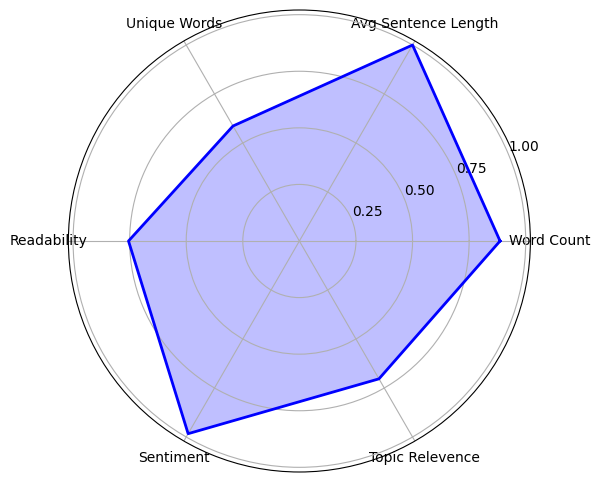

19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step
Results saved to /Users/shivam/Downloads/essay_scoring_results.csv
Test Mean Absolute Error (MAE): 1.5200
Test Root Mean Squared Error (RMSE): 1.8224


In [ ]:
import spacy
from tensorflow.keras.preprocessing.text import Tokenizer # type: ignore
from tensorflow.keras.preprocessing.sequence import pad_sequences # type: ignore
from keras.callbacks import ReduceLROnPlateau
from xgboost import XGBRegressor
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import train_test_split 
from keras.models import Sequential, load_model
from keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from keras.optimizers import Adam
import numpy as np
import pandas as pd
from textstat import textstat
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
import requests
import transformers
import joblib
import os
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.isotonic import IsotonicRegression


nlp = spacy.load('en_core_web_sm')
sentiment_analyzer = SentimentIntensityAnalyzer()
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

def extract_features(essay,topic):
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Calculate topic relevance
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    # Combine features
    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance
    }

    return features

# Load data
df = pd.read_csv('essays.csv')

# Separate text data and target scores
texts = df['Essay Answer']  # For RNN
scores = df['Score']  # Target
topic = df['Essay Question']
features = [extract_features(essay,topic) for essay in texts]
features_df = pd.DataFrame(features)

# Prepare the engineered features for Gradient Boosting
X_engineered = features_df
y = scores

# Prepare text data for RNN
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(texts)

# Tokenize and pad sequences
X_text = tokenizer.texts_to_sequences(texts)
X_text = pad_sequences(X_text, maxlen=500)  # Ensure consistent length

# Train-test split
X_engineered_train, X_engineered_test, X_text_train, X_text_test, y_train, y_test = train_test_split(
    X_engineered, X_text, y, test_size=0.2, random_state=42
)

# Calculate class weights
sample_weights = compute_sample_weight("balanced", y_train)
sample_weights /= sample_weights.sum()  # Normalize weights

# Train the SVM model with sample weights
svm_model = SVR(C=10, epsilon=0.1, gamma='scale', kernel='rbf')
# svm_model = SVR()
svm_model.fit(X_engineered_train, y_train, sample_weight=sample_weights)

y_pred = svm_model.predict(X_engineered_test)
mae_svm = mean_absolute_error(y_test, y_pred)
print(f"SVM: MAE = {mae_svm:.4f}")

# Save the Gradient Boosting model
print(type(svm_model))
print(svm_model.get_params())

# RNN Model for Text
vocab_size = 5000  # Match the tokenizer

# Learning rate scheduler
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

rnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, input_length=500),
    Bidirectional(LSTM(128, return_sequences=False, kernel_regularizer="l2")),  # L2 Regularization
    Dropout(0.5),  # Increased Dropout
    Dense(64, activation='relu', kernel_regularizer="l2"),
    Dropout(0.5),  # Additional Dropout Layer
    Dense(1)
])
rnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='mae', metrics=['mae'])

# Train RNN
rnn_model.fit(X_text_train, y_train, batch_size=32, epochs=15, validation_split=0.2)

# Combine predictions into a new feature set
rnn_train_pred = rnn_model.predict(X_text_train)
svm_train_pred = svm_model.predict(X_engineered_train)
stacked_X_train = np.vstack((svm_train_pred, rnn_train_pred.flatten())).T

print(f"RNN Train Pred Shape: {rnn_train_pred.shape}")
print(f"SVM Train Pred Shape: {svm_train_pred.shape}")
print(f"Concat Train Shape (vstack): {stacked_X_train.shape}")

rnn_test_pred = rnn_model.predict(X_text_test)
svm_test_pred = svm_model.predict(X_engineered_test)
stacked_X_test = np.vstack((svm_test_pred, rnn_test_pred.flatten())).T

print(f"RNN Test Pred Shape: {rnn_test_pred.shape}")
print(f"SVM Test Pred Shape: {svm_test_pred.shape}")
print(f"Concat Test Shape (vstack): {stacked_X_test.shape}")

# Train meta-model on the combined predictions
meta_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.01,
    objective='reg:squarederror',  # Regression objective
    random_state=42
)
meta_model.fit(stacked_X_train, y_train) 

# Compute MAE for Stacked Model
mae_svm = mean_absolute_error(y_test, svm_test_pred)

# Compute MAE for RNN Model
mae_rnn = mean_absolute_error(y_test, rnn_test_pred)

print(f'Mean Absolute Error (MAE) for SVM Model: {mae_svm}')
print(f'Mean Absolute Error (MAE) for RNN Model: {mae_rnn}')

# Final predictions
y_pred_stacked = meta_model.predict(stacked_X_test)

# Evaluate MAE for combined model
mae_combined = mean_absolute_error(y_test, y_pred_stacked)
print(f'Mean Absolute Error (MAE) for Combined Model: {mae_combined}')

# Calibration of predictions
calibrator = IsotonicRegression()
calibrator.fit(y_pred_stacked, y_test)

# Apply calibration
y_pred_calibrated = calibrator.predict(y_pred_stacked)

# Final Evaluation
mae_calibrated = mean_absolute_error(y_test, y_pred_calibrated)
print(f'Mean Absolute Error (MAE) after Calibration: {mae_calibrated}')

def check_plagiarism(essay, google_api_key, search_engine_id):
    sentences = essay.split(". ")  # Split into sentences
    plagiarism_count = 0

    for sentence in sentences:
        query = sentence.strip()
        response = requests.get(    
            "https://www.googleapis.com/customsearch/v1",
            params={
                "key": google_api_key,
                "cx": search_engine_id,
                "q": query,
            },
        ).json()
        if response.get("searchInformation", {}).get("totalResults", "0") != "0":
            plagiarism_count += 1

    plagiarism_score = plagiarism_count / len(sentences) if len(sentences) > 0 else 0
    return plagiarism_score

# Expected Ranges for Feedback
expected_ranges = {
    "Word Count": (250, 600),
    "Avg Sentence Length": (10, 25),
    "Unique Words": (100, 350),
    "Lexical Density": (0.4, 0.7),
    "TTR": (0.3, 0.7),
    "Nouns": (30, 200),
    "Verbs": (20, 100),
    "Readability": (5, 20),
    "Sentiment": (-1, 1),
    "Topic Relevence": (0,1)
}

feature_labels = [
    "Word Count", "Avg Sentence Length", "Unique Words", "Lexical Density", "TTR",
    "Nouns", "Verbs", "Readability", "Sentiment", "Topic Relevence"
]

# Function to provide feedback based on the feature values and expected ranges
def generate_feedback(features, feature_labels):
    feedback = []
    for i, feature in enumerate(features):
        label = feature_labels[i]
        min_range, max_range = expected_ranges[label]
        if label == "Sentiment":  # Special handling for sentiment
            sentiment_feedback = "positive" if feature > 0 else "neutral/negative"
            feedback.append(f"Sentiment: {feature:.2f} , This is a {sentiment_feedback} tone, which is good for positivity.")
        elif min_range <= feature <= max_range:
            feedback.append(f"{label} is {feature:.2f} , this value is within the expected good range, the student has done a great job!")
        else:
            if feature < min_range:
                feedback.append(f"{label} is {feature:.2f} , the student should consider increasing this value for better quality.")
            else:
                feedback.append(f"{label} is {feature:.2f} , this value is quite high, which might indicate overuse of certain elements.")
    
    return feedback

# Radar chart plotting function
def plot_radar_chart(features, labels, final_score, upper_limits):
    # Normalize features
    normalized_features = normalize_features(features, upper_limits)
    
    # Repeat the first value to close the circle
    normalized_features += normalized_features[:1]
    angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
    angles += angles[:1]

    # Create the radar chart
    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    ax.fill(angles, normalized_features, color='blue', alpha=0.25)
    ax.plot(angles, normalized_features, color='blue', linewidth=2)

    # Add labels
    ax.set_yticks([0.25, 0.5, 0.75, 1])  # Normalized scale
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=10)

    # Add final score in the center
    # ax.text(0, 0, f"Score: {final_score:.2f}", ha="left", va="bottom", fontsize=16, color="red",bbox=dict(facecolor="white", edgecolor="red", boxstyle="round,pad=0.3"))

    plt.show()

# Function to normalize features
def normalize_features(features, upper_limits):
    normalized = [min(f / u, 1) for f, u in zip(features, upper_limits)]
    return normalized

# Simulating AI detection for demonstration
def check_ai_generated(text):
    model = transformers.AutoModelForSequenceClassification.from_pretrained("roberta-base-openai-detector")
    tokenizer = transformers.AutoTokenizer.from_pretrained("roberta-base-openai-detector")

    inputs = tokenizer(text, return_tensors="pt")
    outputs = model(**inputs)
    prediction = outputs.logits.argmax(dim=1).item()

    result = "Real" if prediction == 0 else "Fake"
    explanation = "AI-generated content detected." if result == "Fake" else "Human-written content detected."
    return result, explanation

# Example input essay
new_topic = """ Influencers and their impact on society """
new_essay = """
    ""Influencers"" in a general sense is used to refer to social-media influencers: individuals who utilise their social media platforms and create content to appeal to an online audience. The idea that influencers have an impact on society is definitive; in a growing modern world, our global population relies on the internet to communicate and thrive. Thus, it may be argued whether influencers have a positive or negative impact on society.In a world that uses devices and the internet on a day-to-day basis, influencers are able to reach a very large audience. This predominantly consists of a younger demographic, and thus influencers can have a very large responsibility in shaping the views and values of this younger demographic. For instance, a study in 2019 showed that the use of social media in Hong Kong brought about a greater turnout in local elections; this is one example of the importance of influencers in shaping the political culture of a nation. Living in an era of conflict can also mean that the media becomes extremely polarised; thus the voice of an influencer becomes crucial in ensuring that they are expressing their voice in an ethical, considerable manner, and presenting facts accurately. If this is done appropriately, an influencer has a positive impact on spreading awareness on local and global issues of importance.It may also stand that influencers have a negative impact on society. Seeing as the prospect of becoming an influencer is becoming relatively more attractive by the day, due to the limited skillset required and the comfortable pay, this may work to negatively impact the economic growth of a state. Employment in fewer sectors that require greater skill and education, such as those of IT workers and doctors, may result in a fall in the economic development of a nation, and perhaps brain-drain, as the skilled workers remaining may look to work elsewhere in search of greater opportunities.Thus, it it may not be argued that influencers have an impact on society, especially in our technologically-driven world. However, it can be argued whether their impact is positive and negative: positive due to the power they hold to shape the views of the youth for the better, or negative because of the attractive nature of the job, and thus the potential decrease in opportunities available for more skilled workers (inherently impacting the development of a state)"""

# Preprocess for the RNN model
max_vocab_size = 5000  # Should match the tokenizer's configuration during training
max_sequence_length = 300  # Should match the padding length during training
tokenizer = Tokenizer(num_words=max_vocab_size)
tokenizer.fit_on_texts([new_essay])  # Ensure tokenizer is initialized with training data
sequence = tokenizer.texts_to_sequences([new_essay])
padded_sequence = pad_sequences(sequence, maxlen=max_sequence_length)

# Example usage

def extract_features_usage(essay,topic):
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar
    pos_count = {
        'NOUN': len([token for token in doc if token.pos_ == 'NOUN']),
        'VERB': len([token for token in doc if token.pos_ == 'VERB'])
    }

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Calculate topic relevance
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    # Combine features into a list
    features = [
        word_count,
        avg_sentence_length,
        unique_words,
        lexical_density,
        ttr,
        pos_count['NOUN'],
        pos_count['VERB'],
        flesch_kincaid,
        sentiment,
        topic_relevance
    ]

    return features

tokenizer = Tokenizer(num_words=max_vocab_size)
tokenizer.fit_on_texts([new_essay])  # Ensure tokenizer is initialized with training data

# Tokenizer should be fitted on the entire training set
sequence = tokenizer.texts_to_sequences([new_essay])
padded_sequence = pad_sequences(sequence, maxlen=max_sequence_length)

# Extract engineered features
engineered_features = np.array(extract_features_usage(new_essay,new_topic)).reshape(1, -1)
features = engineered_features[0].tolist()
print(features)

# Generate feedback based on the extracted features
feedback = generate_feedback(features, feature_labels)

# Plagiarism Checking
essay=new_essay
topic=new_topic
google_api_key = " xxx "
search_engine_id = "xxx"
 
plagiarism = check_plagiarism(essay, google_api_key, search_engine_id) if google_api_key else 0

result = check_ai_generated(new_essay)
    
# Print the results
print(result)
print("\n")

if 0 <= plagiarism < 0.2:
    print(f"Plagiarism Score: {plagiarism:.2f} - Low plagiarism detected. Great job on originality!")
elif 0.2 <= plagiarism < 0.5:
    print(f"Plagiarism Score: {plagiarism:.2f} - Moderate plagiarism detected. Consider rephrasing or citing sources.")
elif 0.5 <= plagiarism <= 1:
    print(f"Plagiarism Score: {plagiarism:.2f} - High plagiarism detected! Significant parts of the essay may need to be rewritten.")
else:
    print("Invalid plagiarism score. Please check the input.")

print("\n")

# Print each feature in a new line
feature_names = [
    "Word Count",
    "Average Sentence Length",
    "Unique Words",
    "Lexical Density",
    "TTR",
    "NOUN Count",
    "VERB Count",
    "Flesch-Kincaid Grade",
    "Sentiment"
]

for name, value in zip(feature_names, features):
    print(f"{name}: {value}")

# Predict using both models
text_score = rnn_model.predict(padded_sequence).flatten()[0]  # RNN prediction
engineered_score = svm_model.predict(engineered_features)[0]   # Gradient Boosting prediction

# Step 2: Combine predictions into a single array for the meta-model
stacked_inputs = np.column_stack((engineered_score, text_score))

# Step 3: Use the meta-model for the final prediction
final_score = meta_model.predict(stacked_inputs)

final_calibrated_score = calibrator.predict(final_score)

# Output the result
print("\nPredicted Score from RNN:", text_score)
print("Predicted Score from Engineered Features:", engineered_score)
print("Final Predicted Score (Meta):", final_score[0], "of 10")
print("Final Predicted Score (Meta + Calibrated):", final_calibrated_score[0], "of 10")
print("\n")

# Print feedback
for line in feedback:
    print(line)

# Using filter to remove elements
features_filtered = features[:3] + features[7:]
print (features_filtered)

feature_labels_filtered = [
    "Word Count", "Avg Sentence Length", "Unique Words", "Readability", "Sentiment","Topic Relevence"
]
upper_limits = [450, 20, 300, 20, 1, 1]
plot_radar_chart(features_filtered, feature_labels_filtered, final_score, upper_limits)

# Generate predictions for the test set
rnn_test_pred = rnn_model.predict(X_text_test).flatten()
svm_test_pred = svm_model.predict(X_engineered_test)

# Combine predictions into a new feature set for meta-model
stacked_X_test = np.vstack((svm_test_pred, rnn_test_pred)).T

# Meta-model predictions
final_test_pred = meta_model.predict(stacked_X_test)

# Apply calibration
final_test_pred_calibrated = calibrator.predict(final_test_pred)

# Create DataFrame with the required columns
results_df = pd.DataFrame({
    "Essay Question": df["Essay Question"].iloc[y_test.index],  # Get corresponding test questions
    "Essay Answer": texts.iloc[y_test.index],  # Get corresponding test answers
    "Actual Score": y_test.values,
    "Predicted Score": final_test_pred_calibrated,
    "Absolute Difference": np.abs(y_test.values - final_test_pred_calibrated)
})

# Save to CSV
output_csv_path = "/Users/shivam/Downloads/essay_scoring_results.csv"
results_df.to_csv(output_csv_path, index=False)

print(f"Results saved to {output_csv_path}")

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE
test_mae = mean_absolute_error(y_test, final_test_pred_calibrated)
print(f"Test Mean Absolute Error (MAE): {test_mae:.4f}")

# Calculate RMSE
test_rmse = np.sqrt(mean_squared_error(y_test, final_test_pred_calibrated))
print(f"Test Root Mean Squared Error (RMSE): {test_rmse:.4f}")



### RNN + GB

In [ ]:
import spacy
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split 
from sentence_transformers import SentenceTransformer
from keras.models import Sequential
from keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from keras.optimizers import Adam
import numpy as np
import pandas as pd
from textstat import textstat
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
import numpy as np
import requests
import transformers


nlp = spacy.load('en_core_web_sm')
sentiment_analyzer = SentimentIntensityAnalyzer()
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

def extract_features(essay,topic):
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Calculate topic relevance
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    # Combine features
    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance
    }

    return features

# Load data
df = pd.read_csv('essays.csv')

# Separate text data and target scores
topic = df['Essay Question']
texts = df['Essay Answer']  # For RNN
scores = df['Score']  # Target
features = [extract_features(essay,topic) for essay in texts]
features_df = pd.DataFrame(features)

# Prepare the engineered features for Gradient Boosting
X_engineered = features_df
y = scores

# Prepare text data for RNN
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(texts)

# Tokenize and pad sequences
X_text = tokenizer.texts_to_sequences(texts)
X_text = pad_sequences(X_text, maxlen=500)  # Ensure consistent length

# Train-test split
X_engineered_train, X_engineered_test, X_text_train, X_text_test, y_train, y_test = train_test_split(
    X_engineered, X_text, y, test_size=0.2, random_state=42
)

# Gradient Boosting Model for Engineered Features
gb_model = GradientBoostingRegressor(n_estimators=500,
    max_depth=6,
    learning_rate=0.01,
    random_state=42)
gb_model.fit(X_engineered_train, y_train)

# RNN Model for Text
vocab_size = 5000  # Match the tokenizer
rnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, input_length=500),
    Bidirectional(LSTM(128, return_sequences=False)),
    Dropout(0.3),
    Dense(64, activation='gelu'),
    Dense(1)
])
rnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='mse', metrics=['mae'])

# Train RNN
rnn_model.fit(X_text_train, y_train, batch_size=32, epochs=10, validation_split=0.2)

# Predict with the models
text_predictions = rnn_model.predict(X_text_test)
engineered_predictions = gb_model.predict(X_engineered_test)

# Ensemble predictions (e.g., averaging)
final_predictions = (text_predictions.flatten() + engineered_predictions) / 2

# Evaluation
mae = np.mean(np.abs(final_predictions - y_test))
print(f"Mean Absolute Error (MAE): {mae}")

def check_plagiarism(essay, google_api_key, search_engine_id):
    sentences = essay.split(". ")  # Split into sentences
    plagiarism_count = 0

    for sentence in sentences:
        query = sentence.strip()
        response = requests.get(
            "https://www.googleapis.com/customsearch/v1",
            params={
                "key": google_api_key,
                "cx": search_engine_id,
                "q": query,
            },
        ).json()
        if response.get("searchInformation", {}).get("totalResults", "0") != "0":
            plagiarism_count += 1

    plagiarism_score = plagiarism_count / len(sentences) if len(sentences) > 0 else 0
    return plagiarism_score

# Expected Ranges for Feedback
expected_ranges = {
    "Word Count": (250, 600),
    "Avg Sentence Length": (10, 25),
    "Unique Words": (100, 350),
    "Lexical Density": (0.4, 0.7),
    "TTR": (0.3, 0.7),
    "Nouns": (30, 200),
    "Verbs": (20, 100),
    "Readability": (5, 20),
    "Sentiment": (-1, 1)
}

feature_labels = [
    "Word Count", "Avg Sentence Length", "Unique Words", "Lexical Density", "TTR",
    "Nouns", "Verbs", "Readability", "Sentiment"
]

# Function to provide feedback based on the feature values and expected ranges
def generate_feedback(features, feature_labels):
    feedback = []
    for i, feature in enumerate(features):
        label = feature_labels[i]
        min_range, max_range = expected_ranges[label]
        if label == "Sentiment":  # Special handling for sentiment
            sentiment_feedback = "positive" if feature > 0 else "neutral/negative"
            feedback.append(f"Sentiment: {feature:.2f} , This is a {sentiment_feedback} tone, which is good for positivity.")
        elif min_range <= feature <= max_range:
            feedback.append(f"{label} is {feature:.2f} , this value is within the expected good range, the student has done a great job!")
        else:
            if feature < min_range:
                feedback.append(f"{label} is {feature:.2f} , the student should consider increasing this value for better quality.")
            else:
                feedback.append(f"{label} is {feature:.2f} , this value is quite high, which might indicate overuse of certain elements.")
    
    return feedback

# Radar chart plotting function
def plot_radar_chart(features, labels, final_score, upper_limits):
    # Normalize features
    normalized_features = normalize_features(features, upper_limits)
    
    # Repeat the first value to close the circle
    normalized_features += normalized_features[:1]
    angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
    angles += angles[:1]

    # Create the radar chart
    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    ax.fill(angles, normalized_features, color='blue', alpha=0.25)
    ax.plot(angles, normalized_features, color='blue', linewidth=2)

    # Add labels
    ax.set_yticks([0.25, 0.5, 0.75, 1])  # Normalized scale
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=10)

    # Add final score in the center
    # ax.text(0, 0, f"Score: {final_score:.2f}", ha="left", va="bottom", fontsize=16, color="red",bbox=dict(facecolor="white", edgecolor="red", boxstyle="round,pad=0.3"))

    plt.show()

# Function to normalize features
def normalize_features(features, upper_limits):
    normalized = [min(f / u, 1) for f, u in zip(features, upper_limits)]
    return normalized

# Simulating AI detection for demonstration
def check_ai_generated(text):
    model = transformers.AutoModelForSequenceClassification.from_pretrained("roberta-base-openai-detector")
    tokenizer = transformers.AutoTokenizer.from_pretrained("roberta-base-openai-detector")

    inputs = tokenizer(text, return_tensors="pt")
    outputs = model(**inputs)
    prediction = outputs.logits.argmax(dim=1).item()

    if prediction == 0:
        return "Real"  # Human-written
    else:
        return "Fake"  # AI-generated
    
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict with the models
text_predictions = rnn_model.predict(X_text_test)
engineered_predictions = gb_model.predict(X_engineered_test)

# Ensemble predictions (e.g., averaging)
final_predictions = (text_predictions.flatten() + engineered_predictions) / 2

# Evaluate on test set
mae = mean_absolute_error(y_test, final_predictions)
rmse = np.sqrt(mean_squared_error(y_test, final_predictions))

print(f"Test Mean Absolute Error (MAE): {mae:.4f}")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.4f}")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Epoch 1/10


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 289ms/step - loss: 14.5348 - mae: 2.9841 - val_loss: 3.2022 - val_mae: 1.4913
Epoch 2/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 319ms/step - loss: 3.5879 - mae: 1.5806 - val_loss: 3.1662 - val_mae: 1.4801
Epoch 3/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 378ms/step - loss: 2.6631 - mae: 1.3286 - val_loss: 3.4195 - val_mae: 1.4884
Epoch 4/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 377ms/step - loss: 1.6400 - mae: 1.0081 - val_loss: 4.0863 - val_mae: 1.6159
Epoch 5/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 378ms/step - loss: 1.0331 - mae: 0.7947 - val_loss: 4.2517 - val_mae: 1.6506
Epoch 6/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 375ms/step - loss: 0.6316 - mae: 0.6272 - val_loss: 4.2697 - val_mae: 1.6539
Epoch 7/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 376ms/step - loss: 0.4275 - mae: 0.5139 - val_loss: 4.1159 - val_mae: 1.6275
Epoch 8/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 383ms/step - loss: 0.3270 - mae: 0.4555 - val_loss: 4.0641 - val_mae: 1.6149
Epoch 9/10
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 379ms/step - los

### Merging the vectors before XGB

In [ ]:
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.isotonic import IsotonicRegression
import numpy as np
import pandas as pd

# Define the BiLSTM model with 128 units
def create_bilstm_model(vocab_size, max_sequence_length):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=128, input_length=max_sequence_length),
        Bidirectional(LSTM(128, return_sequences=False, kernel_regularizer="l2")),  # 128 units as requested
        Dropout(0.5),
        Dense(64, activation='relu', kernel_regularizer="l2"),
        Dropout(0.5),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mae', metrics=['mae'])
    return model

# Load and prepare data
df = pd.read_csv('essays.csv')  
texts = df['Essay Answer']
scores = df['Score']
topics = df['Essay Question']

# Extract features
features = [extract_features(essay, topic) for essay, topic in zip(texts, topics)]
features_df = pd.DataFrame(features)

# Prepare text data
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(texts)
X_text = tokenizer.texts_to_sequences(texts)
X_text = pad_sequences(X_text, maxlen=500)

# Train-test split
X_engineered_train, X_engineered_test, X_text_train, X_text_test, y_train, y_test = train_test_split(
    features_df, X_text, scores, test_size=0.2, random_state=42
)

# Create and train BiLSTM model
vocab_size = 5000
max_sequence_length = 500
bilstm_model = create_bilstm_model(vocab_size, max_sequence_length)

# Train BiLSTM
history = bilstm_model.fit(
    X_text_train, 
    y_train,
    batch_size=32,
    epochs=15,
    validation_split=0.2
)

# Extract BiLSTM features
feature_extractor = Sequential([
    bilstm_model.layers[0],  # Embedding
    bilstm_model.layers[1],  # BiLSTM (128*2=256 features)
])

bilstm_train_features = feature_extractor.predict(X_text_train)
bilstm_test_features = feature_extractor.predict(X_text_test)

# Combine BiLSTM features with engineered features directly
# No SVR training - just use the engineered features as-is
combined_train_features = np.hstack((bilstm_train_features, X_engineered_train.values))
combined_test_features = np.hstack((bilstm_test_features, X_engineered_test.values))

print(f"BiLSTM Train Pred Shape: {bilstm_train_features.shape}")
print(f"EF Train Shape: {X_engineered_train.shape}")
print(f"Concat Train Shape (hstack): {combined_train_features.shape}")

print(f"Sample of BiLSTM Train: {bilstm_train_features[0]}")
print(f"Sample of EF Train: {X_engineered_train}")
print(f"Sample of Combined Train: {combined_train_features[0]}")

print(f"BiLSTM Test Pred Shape: {bilstm_test_features.shape}")
print(f"EF Test Shape: {X_engineered_test.shape}")
print(f"Concat Test Shape (hstack): {combined_test_features.shape}")

# Train XGBoost on the combined features
xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.01,
    objective='reg:squarederror',
    random_state=42
)
xgb_model.fit(combined_train_features, y_train)

# Make predictions
final_predictions = xgb_model.predict(combined_test_features)

# Optional: Apply calibration
calibrator = IsotonicRegression()
calibrator.fit(final_predictions, y_test)
calibrated_predictions = calibrator.predict(final_predictions)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, calibrated_predictions)
rmse = np.sqrt(mean_squared_error(y_test, calibrated_predictions))

print(f"Test Mean Absolute Error (MAE): {mae:.4f}")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.4f}")

Epoch 1/15


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


60/60 ━━━━━━━━━━━━━━━━━━━━ 17s 255ms/step - loss: 7.1314 - mae: 3.4364 - val_loss: 2.7020 - val_mae: 1.5106
Epoch 2/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 314ms/step - loss: 2.7150 - mae: 1.7973 - val_loss: 1.9045 - val_mae: 1.4519
Epoch 3/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 369ms/step - loss: 2.1848 - mae: 1.7860 - val_loss: 1.9404 - val_mae: 1.6512
Epoch 4/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 371ms/step - loss: 2.1217 - mae: 1.8472 - val_loss: 1.6707 - val_mae: 1.4263
Epoch 5/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 370ms/step - loss: 1.7830 - mae: 1.5398 - val_loss: 1.7904 - val_mae: 1.5651
Epoch 6/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 371ms/step - loss: 1.7205 - mae: 1.5040 - val_loss: 1.6412 - val_mae: 1.4504
Epoch 7/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 367ms/step - loss: 1.6090 - mae: 1.4141 - val_loss: 1.6802 - val_mae: 1.5027
Epoch 8/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 374ms/step - loss: 1.5695 - mae: 1.3931 - val_loss: 1.6684 - val_mae: 1.5114
Epoch 9/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 26s 440ms/step - loss

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


SVM: MAE = 1.4793
<class 'sklearn.svm._classes.SVR'>
{'C': 10, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 18s 259ms/step - loss: 7.0776 - mae: 3.3697 - val_loss: 2.6609 - val_mae: 1.4352
Epoch 2/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 313ms/step - loss: 2.7560 - mae: 1.8056 - val_loss: 1.9175 - val_mae: 1.4346
Epoch 3/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 376ms/step - loss: 2.2042 - mae: 1.7806 - val_loss: 1.7855 - val_mae: 1.4778
Epoch 4/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 25s 420ms/step - loss: 2.0615 - mae: 1.7735 - val_loss: 1.6704 - val_mae: 1.4264
Epoch 5/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 388ms/step - loss: 1.9526 - mae: 1.7154 - val_loss: 1.7120 - val_mae: 1.4905
Epoch 6/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 373ms/step - loss: 1.8092 - mae: 1.5812 - val_loss: 1.6655 - val_mae: 1.4563
Epoch 7/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 382ms/step - loss: 1.6459 - mae: 1.4368 - val_loss: 1.6212 - val_mae: 1.4259
Epoch 8/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 375ms/step - loss: 1.5788 - mae: 1.3826 - val_loss: 1.6520 - val_mae: 1.4655
Epoch 9/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 367ms/

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of the model checkpoint at roberta-base-openai-detector were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClas

('Fake', 'AI-generated content detected.')


Plagiarism Score: 1.00 - High plagiarism detected! Significant parts of the essay may need to be rewritten.


Word Count: 399.0
Average Sentence Length: 30.692307692307693
Unique Words: 176.0
Lexical Density: 0.44110275689223055
TTR: 0.44110275689223055
NOUN Count: 95.0
VERB Count: 50.0
Flesch-Kincaid Grade: 15.1
Sentiment: 0.9831
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step

Predicted Score from RNN: 5.255796
Predicted Score from Engineered Features: 6.420876195505758
Final Predicted Score (Meta): 6.246161 of 10
Final Predicted Score (Meta + Calibrated): 5.845137 of 10


Word Count is 399.00 , this value is within the expected good range, the student has done a great job!
Avg Sentence Length is 30.69 , this value is quite high, which might indicate overuse of certain elements.
Unique Words is 176.00 , this value is within the expected good range, the student has done a great job!
Lexical Density is 0.44 , this value is within the expected good ra

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


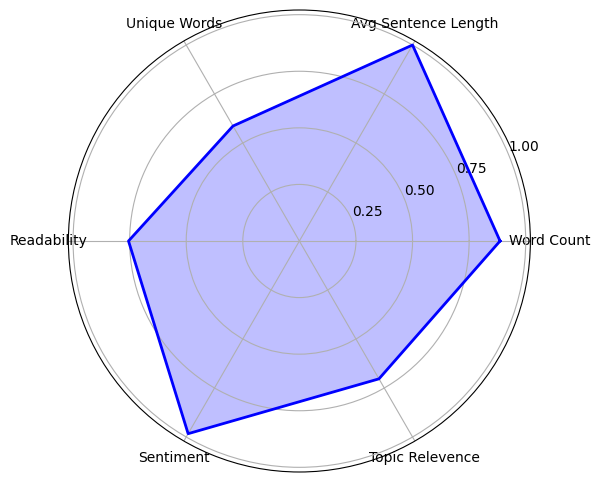

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step
Results saved to /Users/shivam/Downloads/essay_scoring_results.csv
Test Mean Absolute Error (MAE): 1.5105
Test Root Mean Squared Error (RMSE): 1.8091


In [ ]:
import spacy
from tensorflow.keras.preprocessing.text import Tokenizer # type: ignore
from tensorflow.keras.preprocessing.sequence import pad_sequences # type: ignore
from keras.callbacks import ReduceLROnPlateau
from xgboost import XGBRegressor
from sentence_transformers import SentenceTransformer
from sklearn.model_selection import train_test_split 
from keras.models import Sequential, load_model
from keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from keras.optimizers import Adam
import numpy as np
import pandas as pd
from textstat import textstat
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
import requests
import transformers
import joblib
import os
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.isotonic import IsotonicRegression


nlp = spacy.load('en_core_web_sm')
sentiment_analyzer = SentimentIntensityAnalyzer()
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

def extract_features(essay,topic):
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Calculate topic relevance
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    # Combine features
    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance
    }

    return features

# Load data
df = pd.read_csv('essays.csv')

# Separate text data and target scores
texts = df['Essay Answer']  # For RNN
scores = df['Score']  # Target
topic = df['Essay Question']
features = [extract_features(essay,topic) for essay in texts]
features_df = pd.DataFrame(features)

# Prepare the engineered features for Gradient Boosting
X_engineered = features_df
y = scores

# Prepare text data for RNN
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(texts)

# Tokenize and pad sequences
X_text = tokenizer.texts_to_sequences(texts)
X_text = pad_sequences(X_text, maxlen=500)  # Ensure consistent length

# Train-test split
X_engineered_train, X_engineered_test, X_text_train, X_text_test, y_train, y_test = train_test_split(
    X_engineered, X_text, y, test_size=0.2, random_state=42
)

# Calculate class weights
sample_weights = compute_sample_weight("balanced", y_train)
sample_weights /= sample_weights.sum()  # Normalize weights

# Train the SVM model with sample weights
svm_model = SVR(C=10, epsilon=0.1, gamma='scale', kernel='rbf')
# svm_model = SVR()
svm_model.fit(X_engineered_train, y_train, sample_weight=sample_weights)

y_pred = svm_model.predict(X_engineered_test)
mae_svm = mean_absolute_error(y_test, y_pred)
print(f"SVM: MAE = {mae_svm:.4f}")

# Save the Gradient Boosting model
print(type(svm_model))
print(svm_model.get_params())

# RNN Model for Text
vocab_size = 5000  # Match the tokenizer

# Learning rate scheduler
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

rnn_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, input_length=500),
    Bidirectional(LSTM(128, return_sequences=False, kernel_regularizer="l2")),  # L2 Regularization
    Dropout(0.5),  # Increased Dropout
    Dense(64, activation='relu', kernel_regularizer="l2"),
    Dropout(0.5),  # Additional Dropout Layer
    Dense(1)
])
rnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='mae', metrics=['mae'])

# Train RNN
rnn_model.fit(X_text_train, y_train, batch_size=32, epochs=15, validation_split=0.2)

# Combine predictions into a new feature set
rnn_train_pred = rnn_model.predict(X_text_train)
svm_train_pred = svm_model.predict(X_engineered_train)
stacked_X_train = np.vstack((svm_train_pred, rnn_train_pred.flatten())).T

print(f"RNN Train Pred Shape: {rnn_train_pred.shape}")
print(f"SVM Train Pred Shape: {svm_train_pred.shape}")
print(f"Concat Train Shape (vstack): {stacked_X_train.shape}")

print(f"Sample of RNN  Train Pred: {rnn_train_pred[0]}")
print(f"Sample of SVM  Train Pred: {svm_train_pred[0]}")
print(f"Sample of vStack Train Pred: {stacked_X_train[0]}")

rnn_test_pred = rnn_model.predict(X_text_test)
svm_test_pred = svm_model.predict(X_engineered_test)
stacked_X_test = np.vstack((svm_test_pred, rnn_test_pred.flatten())).T

print(f"RNN Test Pred Shape: {rnn_test_pred.shape}")
print(f"SVM Test Pred Shape: {svm_test_pred.shape}")
print(f"Concat Test Shape (vstack): {stacked_X_test.shape}")

# Train meta-model on the combined predictions
meta_model = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.01,
    objective='reg:squarederror',  # Regression objective
    random_state=42
)
meta_model.fit(stacked_X_train, y_train) 

# Compute MAE for Stacked Model
mae_svm = mean_absolute_error(y_test, svm_test_pred)

# Compute MAE for RNN Model
mae_rnn = mean_absolute_error(y_test, rnn_test_pred)

print(f'Mean Absolute Error (MAE) for SVM Model: {mae_svm}')
print(f'Mean Absolute Error (MAE) for RNN Model: {mae_rnn}')

# Final predictions
y_pred_stacked = meta_model.predict(stacked_X_test)

# Evaluate MAE for combined model
mae_combined = mean_absolute_error(y_test, y_pred_stacked)
print(f'Mean Absolute Error (MAE) for Combined Model: {mae_combined}')

# Calibration of predictions
calibrator = IsotonicRegression()
calibrator.fit(y_pred_stacked, y_test)

# Apply calibration
y_pred_calibrated = calibrator.predict(y_pred_stacked)

# Final Evaluation
mae_calibrated = mean_absolute_error(y_test, y_pred_calibrated)
print(f'Mean Absolute Error (MAE) after Calibration: {mae_calibrated}')

def check_plagiarism(essay, google_api_key, search_engine_id):
    sentences = essay.split(". ")  # Split into sentences
    plagiarism_count = 0

    for sentence in sentences:
        query = sentence.strip()
        response = requests.get(    
            "https://www.googleapis.com/customsearch/v1",
            params={
                "key": google_api_key,
                "cx": search_engine_id,
                "q": query,
            },
        ).json()
        if response.get("searchInformation", {}).get("totalResults", "0") != "0":
            plagiarism_count += 1

    plagiarism_score = plagiarism_count / len(sentences) if len(sentences) > 0 else 0
    return plagiarism_score

# Expected Ranges for Feedback
expected_ranges = {
    "Word Count": (250, 600),
    "Avg Sentence Length": (10, 25),
    "Unique Words": (100, 350),
    "Lexical Density": (0.4, 0.7),
    "TTR": (0.3, 0.7),
    "Nouns": (30, 200),
    "Verbs": (20, 100),
    "Readability": (5, 20),
    "Sentiment": (-1, 1),
    "Topic Relevence": (0,1)
}

feature_labels = [
    "Word Count", "Avg Sentence Length", "Unique Words", "Lexical Density", "TTR",
    "Nouns", "Verbs", "Readability", "Sentiment", "Topic Relevence"
]

# Function to provide feedback based on the feature values and expected ranges
def generate_feedback(features, feature_labels):
    feedback = []
    for i, feature in enumerate(features):
        label = feature_labels[i]
        min_range, max_range = expected_ranges[label]
        if label == "Sentiment":  # Special handling for sentiment
            sentiment_feedback = "positive" if feature > 0 else "neutral/negative"
            feedback.append(f"Sentiment: {feature:.2f} , This is a {sentiment_feedback} tone, which is good for positivity.")
        elif min_range <= feature <= max_range:
            feedback.append(f"{label} is {feature:.2f} , this value is within the expected good range, the student has done a great job!")
        else:
            if feature < min_range:
                feedback.append(f"{label} is {feature:.2f} , the student should consider increasing this value for better quality.")
            else:
                feedback.append(f"{label} is {feature:.2f} , this value is quite high, which might indicate overuse of certain elements.")
    
    return feedback

# Radar chart plotting function
def plot_radar_chart(features, labels, final_score, upper_limits):
    # Normalize features
    normalized_features = normalize_features(features, upper_limits)
    
    # Repeat the first value to close the circle
    normalized_features += normalized_features[:1]
    angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
    angles += angles[:1]

    # Create the radar chart
    fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
    ax.fill(angles, normalized_features, color='blue', alpha=0.25)
    ax.plot(angles, normalized_features, color='blue', linewidth=2)

    # Add labels
    ax.set_yticks([0.25, 0.5, 0.75, 1])  # Normalized scale
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=10)

    # Add final score in the center
    # ax.text(0, 0, f"Score: {final_score:.2f}", ha="left", va="bottom", fontsize=16, color="red",bbox=dict(facecolor="white", edgecolor="red", boxstyle="round,pad=0.3"))

    plt.show()

# Function to normalize features
def normalize_features(features, upper_limits):
    normalized = [min(f / u, 1) for f, u in zip(features, upper_limits)]
    return normalized

# Simulating AI detection for demonstration
def check_ai_generated(text):
    model = transformers.AutoModelForSequenceClassification.from_pretrained("roberta-base-openai-detector")
    tokenizer = transformers.AutoTokenizer.from_pretrained("roberta-base-openai-detector")

    inputs = tokenizer(text, return_tensors="pt")
    outputs = model(**inputs)
    prediction = outputs.logits.argmax(dim=1).item()

    result = "Real" if prediction == 0 else "Fake"
    explanation = "AI-generated content detected." if result == "Fake" else "Human-written content detected."
    return result, explanation

# Example input essay
new_topic = """ Influencers and their impact on society """
new_essay = """
    ""Influencers"" in a general sense is used to refer to social-media influencers: individuals who utilise their social media platforms and create content to appeal to an online audience. The idea that influencers have an impact on society is definitive; in a growing modern world, our global population relies on the internet to communicate and thrive. Thus, it may be argued whether influencers have a positive or negative impact on society.In a world that uses devices and the internet on a day-to-day basis, influencers are able to reach a very large audience. This predominantly consists of a younger demographic, and thus influencers can have a very large responsibility in shaping the views and values of this younger demographic. For instance, a study in 2019 showed that the use of social media in Hong Kong brought about a greater turnout in local elections; this is one example of the importance of influencers in shaping the political culture of a nation. Living in an era of conflict can also mean that the media becomes extremely polarised; thus the voice of an influencer becomes crucial in ensuring that they are expressing their voice in an ethical, considerable manner, and presenting facts accurately. If this is done appropriately, an influencer has a positive impact on spreading awareness on local and global issues of importance.It may also stand that influencers have a negative impact on society. Seeing as the prospect of becoming an influencer is becoming relatively more attractive by the day, due to the limited skillset required and the comfortable pay, this may work to negatively impact the economic growth of a state. Employment in fewer sectors that require greater skill and education, such as those of IT workers and doctors, may result in a fall in the economic development of a nation, and perhaps brain-drain, as the skilled workers remaining may look to work elsewhere in search of greater opportunities.Thus, it it may not be argued that influencers have an impact on society, especially in our technologically-driven world. However, it can be argued whether their impact is positive and negative: positive due to the power they hold to shape the views of the youth for the better, or negative because of the attractive nature of the job, and thus the potential decrease in opportunities available for more skilled workers (inherently impacting the development of a state)"""

# Preprocess for the RNN model
max_vocab_size = 5000  # Should match the tokenizer's configuration during training
max_sequence_length = 300  # Should match the padding length during training
tokenizer = Tokenizer(num_words=max_vocab_size)
tokenizer.fit_on_texts([new_essay])  # Ensure tokenizer is initialized with training data
sequence = tokenizer.texts_to_sequences([new_essay])
padded_sequence = pad_sequences(sequence, maxlen=max_sequence_length)

# Example usage

def extract_features_usage(essay,topic):
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar
    pos_count = {
        'NOUN': len([token for token in doc if token.pos_ == 'NOUN']),
        'VERB': len([token for token in doc if token.pos_ == 'VERB'])
    }

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Calculate topic relevance
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    # Combine features into a list
    features = [
        word_count,
        avg_sentence_length,
        unique_words,
        lexical_density,
        ttr,
        pos_count['NOUN'],
        pos_count['VERB'],
        flesch_kincaid,
        sentiment,
        topic_relevance
    ]

    return features

tokenizer = Tokenizer(num_words=max_vocab_size)
tokenizer.fit_on_texts([new_essay])  # Ensure tokenizer is initialized with training data

# Tokenizer should be fitted on the entire training set
sequence = tokenizer.texts_to_sequences([new_essay])
padded_sequence = pad_sequences(sequence, maxlen=max_sequence_length)

# Extract engineered features
engineered_features = np.array(extract_features_usage(new_essay,new_topic)).reshape(1, -1)
features = engineered_features[0].tolist()
print(features)

# Generate feedback based on the extracted features
feedback = generate_feedback(features, feature_labels)

# Plagiarism Checking
essay=new_essay
topic=new_topic
google_api_key = " xxx "
search_engine_id = "xxx"
 
plagiarism = check_plagiarism(essay, google_api_key, search_engine_id) if google_api_key else 0

result = check_ai_generated(new_essay)
    
# Print the results
print(result)
print("\n")

if 0 <= plagiarism < 0.2:
    print(f"Plagiarism Score: {plagiarism:.2f} - Low plagiarism detected. Great job on originality!")
elif 0.2 <= plagiarism < 0.5:
    print(f"Plagiarism Score: {plagiarism:.2f} - Moderate plagiarism detected. Consider rephrasing or citing sources.")
elif 0.5 <= plagiarism <= 1:
    print(f"Plagiarism Score: {plagiarism:.2f} - High plagiarism detected! Significant parts of the essay may need to be rewritten.")
else:
    print("Invalid plagiarism score. Please check the input.")

print("\n")

# Print each feature in a new line
feature_names = [
    "Word Count",
    "Average Sentence Length",
    "Unique Words",
    "Lexical Density",
    "TTR",
    "NOUN Count",
    "VERB Count",
    "Flesch-Kincaid Grade",
    "Sentiment"
]

for name, value in zip(feature_names, features):
    print(f"{name}: {value}")

# Predict using both models
text_score = rnn_model.predict(padded_sequence).flatten()[0]  # RNN prediction
engineered_score = svm_model.predict(engineered_features)[0]   # Gradient Boosting prediction

# Step 2: Combine predictions into a single array for the meta-model
stacked_inputs = np.column_stack((engineered_score, text_score))

# Step 3: Use the meta-model for the final prediction
final_score = meta_model.predict(stacked_inputs)

final_calibrated_score = calibrator.predict(final_score)

# Output the result
print("\nPredicted Score from RNN:", text_score)
print("Predicted Score from Engineered Features:", engineered_score)
print("Final Predicted Score (Meta):", final_score[0], "of 10")
print("Final Predicted Score (Meta + Calibrated):", final_calibrated_score[0], "of 10")
print("\n")

# Print feedback
for line in feedback:
    print(line)

# Using filter to remove elements
features_filtered = features[:3] + features[7:]
print (features_filtered)

feature_labels_filtered = [
    "Word Count", "Avg Sentence Length", "Unique Words", "Readability", "Sentiment","Topic Relevence"
]
upper_limits = [450, 20, 300, 20, 1, 1]
plot_radar_chart(features_filtered, feature_labels_filtered, final_score, upper_limits)

# Generate predictions for the test set
rnn_test_pred = rnn_model.predict(X_text_test).flatten()
svm_test_pred = svm_model.predict(X_engineered_test)

# Combine predictions into a new feature set for meta-model
stacked_X_test = np.vstack((svm_test_pred, rnn_test_pred)).T

# Meta-model predictions
final_test_pred = meta_model.predict(stacked_X_test)

# Apply calibration
final_test_pred_calibrated = calibrator.predict(final_test_pred)

# Create DataFrame with the required columns
results_df = pd.DataFrame({
    "Essay Question": df["Essay Question"].iloc[y_test.index],  # Get corresponding test questions
    "Essay Answer": texts.iloc[y_test.index],  # Get corresponding test answers
    "Actual Score": y_test.values,
    "Predicted Score": final_test_pred_calibrated,
    "Absolute Difference": np.abs(y_test.values - final_test_pred_calibrated)
})

# Save to CSV
output_csv_path = "/Users/shivam/Downloads/essay_scoring_results.csv"
results_df.to_csv(output_csv_path, index=False)

print(f"Results saved to {output_csv_path}")

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE
test_mae = mean_absolute_error(y_test, final_test_pred_calibrated)
print(f"Test Mean Absolute Error (MAE): {test_mae:.4f}")

# Calculate RMSE
test_rmse = np.sqrt(mean_squared_error(y_test, final_test_pred_calibrated))
print(f"Test Root Mean Squared Error (RMSE): {test_rmse:.4f}")



In [ ]:
# Calculate MAE
test_mae = mean_absolute_error(y_test, final_test_pred)
print(f"Test Mean Absolute Error (MAE): {test_mae:.4f}")

# Calculate RMSE
test_rmse = np.sqrt(mean_squared_error(y_test, final_test_pred))
print(f"Test Root Mean Squared Error (RMSE): {test_rmse:.4f}")


Test Mean Absolute Error (MAE): 1.6320
Test Root Mean Squared Error (RMSE): 2.0383


In [ ]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, final_predictions)
rmse = np.sqrt(mean_squared_error(y_test, final_predictions))

print(f"Test Mean Absolute Error (MAE): {mae:.4f}")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.4f}")

Test Mean Absolute Error (MAE): 1.6161
Test Root Mean Squared Error (RMSE): 2.0335


### ANN with GloVe embeddings + EF

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
from typing import Dict
import requests
import os
import zipfile
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

class GloVeEmbeddings:
    def __init__(self, embedding_dim=300, glove_path=None):
        """
        Initialize GloVeEmbeddings with embedding dimension and path to the GloVe file.
        
        Parameters:
        - embedding_dim: Dimension of the embeddings (e.g., 50, 100, 200, 300)
        - glove_path: Path to the pre-downloaded GloVe file
        """
        self.embedding_dim = embedding_dim
        self.word_to_vec = {}
        self.glove_path = glove_path

    def load_embeddings(self):
        """
        Load GloVe embeddings into memory from the specified path.
        """
        print(f"Loading {self.embedding_dim}-dimensional GloVe embeddings from {self.glove_path}...")

        if not os.path.exists(self.glove_path):
            raise FileNotFoundError(f"GloVe file not found at {self.glove_path}. Please check the path.")

        with open(self.glove_path, 'r', encoding='utf-8') as f:
            for line in tqdm(f, desc="Loading embeddings"):
                values = line.split()
                word = values[0]
                vector = np.asarray(values[1:], dtype='float32')
                self.word_to_vec[word] = vector

        print(f"Loaded {len(self.word_to_vec)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        """
        Retrieve the embedding for a given word. Returns a zero vector if the word is not found.
        """
        return self.word_to_vec.get(word.lower(), np.zeros(self.embedding_dim))

    def get_text_embedding(self, text: str) -> np.ndarray:
        """
        Compute the average embedding for a given piece of text.
        """
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words]

        if not word_embeddings:
            return np.zeros(self.embedding_dim)

        return np.mean(word_embeddings, axis=0)


def extract_features(essay: str, topic: str) -> np.ndarray:
    """
    Extract linguistic, grammatical, and semantic features from the essay
    """
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar (Nouns and Verbs count)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Topic Relevance
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density, 
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance
    ])

class EssayRegressor(nn.Module):
    def __init__(self, input_dim: int):
        super(EssayRegressor, self).__init__()
        
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)

def prepare_data(csv_path: str, glove: GloVeEmbeddings):
    """
    Prepare data by combining GloVe embeddings and engineered features
    """
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)
    
    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        essay_embedding = glove.get_text_embedding(essay)
        engineered_features = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))
    
    X = np.array(combined_features)
    y = df['Score'].values

    print(f"\nShape of Essay Embeddings : {essay_embedding.shape}")
    print(f"\nShape of EF : {engineered_features.shape}")
    print(f"\nShape of combined features using hstack (X): {X.shape}")

    print(f"\nSample of Essay Embeddings : {essay_embedding[0]}")
    print(f"\nSample of EF : {engineered_features}")
    print(f"\nSample of combined features using hstack (X) : {X[0]}")
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return map(torch.FloatTensor, (X_train, X_test, y_train.reshape(-1, 1), y_test.reshape(-1, 1)))

def train_model(model, X_train, y_train, X_test, y_test, num_epochs=50, batch_size=32, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    print("\nStarting training...")
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for i in range(0, len(X_train), batch_size):
            batch_X = X_train[i:i + batch_size]
            batch_y = y_train[i:i + batch_size]
            
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
        
        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss:.4f}")
    
    # Evaluate Model
    model.eval()
    with torch.no_grad():
        preds = model(X_test)
        mse = mean_squared_error(y_test.numpy(), preds.numpy())
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(y_test.numpy(), preds.numpy())
        print(f"Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")

    return model

def main():
    torch.manual_seed(42)
    np.random.seed(42)

    # Assuming you already have 'glove.6B.300d.txt' in the current directory
    glove_path = '/Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt'

    # Initialize GloVe embeddings without downloading
    glove = GloVeEmbeddings(embedding_dim=300, glove_path=glove_path)

    # Load embeddings from the local file
    glove.load_embeddings()


    X_train, X_test, y_train, y_test = prepare_data('essays.csv', glove)
    
    input_dim = X_train.shape[1]
    model = EssayRegressor(input_dim=input_dim)
    
    model = train_model(model, X_train, y_train, X_test, y_test)
    torch.save(model.state_dict(), 'essay_scoring_model.pth')
    print("\nModel saved successfully!")

if __name__ == "__main__":
    main()

Loading 300-dimensional GloVe embeddings from /Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt...


Loading embeddings: 400000it [00:12, 31763.94it/s]


Loaded 400000 word vectors.
Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [02:21<00:00, 21.01it/s]



Shape of Essay Embeddings : (300,)

Shape of EF : (9,)

Shape of combined features using hstack (X): (2979, 309)

Sample of Essay Embeddings : -0.14461518447035804

Sample of EF : [77.         19.25       61.          0.79220779  0.79220779 18.
 10.          9.6         0.74040204]

Sample of combined features using hstack (X) : [-1.72776881e-01  1.31008354e-01 -6.01833549e-02 -1.20246174e-01
 -2.85495652e-02  8.51383983e-02  1.43371209e-02  4.62081272e-02
  8.48660171e-02 -1.58158721e+00  1.13501673e-01  3.76728782e-02
 -1.10182325e-01  9.79339101e-02  5.49932524e-02  3.24105800e-02
 -1.57298691e-01 -6.02080020e-02 -3.93876928e-02 -6.74706214e-02
  1.46515044e-02  2.04073595e-01  1.65590037e-01  9.72865632e-02
 -1.62316565e-01 -4.63736144e-02  1.92908558e-02 -3.14170252e-02
 -6.09827407e-02  9.80790497e-02  2.41993986e-02  2.23808314e-01
 -1.77860960e-01 -5.20708703e-02 -7.40239531e-01  7.75236816e-02
  1.54662952e-02 -7.11350712e-03 -1.75641006e-02 -8.21547241e-02
  3.86877435e-02 -

### ANN with Word2Vec + EF 

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tqdm import tqdm
import math
import gensim.downloader as api
import spacy
import textstat
from typing import Dict
import warnings

warnings.filterwarnings('ignore')

# Load spaCy and sentiment analyzer
nlp = spacy.load('en_core_web_sm')
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sentiment_analyzer = SentimentIntensityAnalyzer()


### 1. Word2Vec Embeddings Class
class Word2VecEmbeddings:
    def __init__(self):
        """
        Initialize Word2VecEmbeddings class and load the Word2Vec model.
        """
        self.embedding_dim = 300
        self.model = None
        self.load_embeddings()

    def load_embeddings(self):
        """
        Load the Word2Vec model. Download if not available.
        """
        print("Loading Word2Vec model...")
        try:
            self.model = api.load("word2vec-google-news-300")
        except Exception as e:
            print(f"Error loading Word2Vec: {e}")
            raise

        print(f"Loaded {len(self.model.key_to_index)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        """
        Get embedding for a given word. Returns a zero vector if not found.
        """
        return self.model[word] if word in self.model else np.zeros(self.embedding_dim)

    def get_text_embedding(self, text: str) -> np.ndarray:
        """
        Get average embedding for a piece of text.
        """
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words if word in self.model]

        if not word_embeddings:
            return np.zeros(self.embedding_dim)

        return np.mean(word_embeddings, axis=0)


### 2. Feature Extraction
def extract_features(essay, topic):
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness (Type-Token Ratio)
    ttr = unique_words / word_count if word_count > 0 else 0

    # Part-of-Speech Counts (Nouns & Verbs)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability (Flesch-Kincaid Grade Level)
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment (Using VADER)
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Topic Relevance (Cosine Similarity using Word2Vec)
    essay_embedding = w2v.get_text_embedding(essay)
    topic_embedding = w2v.get_text_embedding(topic)
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
            np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding) + 1e-8
    )

    # Combine features
    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance
    }

    return features


### 3. Essay Scoring Neural Network
class EssayRegressor(nn.Module):
    def __init__(self, input_dim):
        super(EssayRegressor, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)


### 4. Data Preparation
def prepare_data(csv_path, w2v):
    print("Loading dataset...")
    df = pd.read_csv(csv_path)

    # Extract features and embeddings
    print("Extracting features and embeddings...")
    essay_embeddings = []
    engineered_features = []

    for _, row in tqdm(df.iterrows(), total=len(df)):
        essay, topic = row['Essay Answer'], row['Essay Question']
        features = extract_features(essay, topic)
        engineered_features.append(list(features.values()))
        essay_embeddings.append(w2v.get_text_embedding(essay))

    essay_embeddings = np.array(essay_embeddings)
    engineered_features = np.array(engineered_features)

    # Combine embeddings with engineered features
    X_combined = np.hstack((essay_embeddings, engineered_features))
    y = df['Score'].values

    print(f"\nShape of Essay Embeddings : {essay_embeddings.shape}")
    print(f"\nShape of EF : {engineered_features.shape}")
    print(f"\nShape of combined features using hstack (X): {X_combined.shape}")

    print(f"\nSample of Essay Embeddings : {essay_embeddings[0]}")
    print(f"\nSample of EF : {engineered_features}")
    print(f"\nSample of combined features using hstack (X) : {X_combined[0]}")

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X_combined, y, test_size=0.2, random_state=42)

    # Convert to tensors
    X_train, X_test = torch.FloatTensor(X_train), torch.FloatTensor(X_test)
    y_train, y_test = torch.FloatTensor(y_train).reshape(-1, 1), torch.FloatTensor(y_test).reshape(-1, 1)

    return X_train, X_test, y_train, y_test


### 5. Model Training
def train_model(model, X_train, y_train, X_test, y_test, epochs=50, batch_size=32, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    print("Training model...")
    for epoch in range(epochs):
        model.train()
        for i in range(0, len(X_train), batch_size):
            batch_X, batch_y = X_train[i:i + batch_size], y_train[i:i + batch_size]
            optimizer.zero_grad()
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()

        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss.item():.4f}")

    # Evaluate model
    model.eval()
    with torch.no_grad():
        predictions = model(X_test)
        mse = mean_squared_error(y_test.numpy(), predictions.numpy())
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(y_test.numpy(), predictions.numpy())
        print(f"Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")

    return model


### 6. Main Function
def main():
    torch.manual_seed(42)
    np.random.seed(42)

    # Initialize Word2Vec (Download if necessary)
    global w2v
    w2v = Word2VecEmbeddings()

    # Prepare Data
    X_train, X_test, y_train, y_test = prepare_data('essays.csv', w2v)

    # Train Model
    model = EssayRegressor(input_dim=X_train.shape[1])
    train_model(model, X_train, y_train, X_test, y_test)

    # Save Model
    torch.save(model.state_dict(), 'word2vec_essay_regressor.pth')
    print("Model saved successfully!")


if __name__ == "__main__":
    main()

Loading Word2Vec model...
Loaded 3000000 word vectors.
Loading dataset...
Extracting features and embeddings...


100%|██████████| 2979/2979 [00:59<00:00, 50.27it/s]



Shape of Essay Embeddings : (2979, 300)

Shape of EF : (2979, 10)

Shape of combined features using hstack (X): (2979, 310)

Sample of Essay Embeddings : [ 0.0383861   0.00948948  0.0604824   0.08403108 -0.07199486  0.03269049
  0.06787204 -0.0673221   0.0759013   0.02905055 -0.05523803 -0.08365203
 -0.0198457   0.05383569 -0.09800641  0.07489537  0.00712105  0.10787018
 -0.00922801 -0.03940188 -0.04984545 -0.00524093 -0.02292852  0.00683803
  0.0333542  -0.01645878 -0.09032892  0.07188034 -0.01624004  0.01000926
  0.00895761  0.01357164 -0.04050137  0.00514082  0.00582488  0.01855425
  0.00493677 -0.00239183  0.04292894  0.04701809  0.08281855  0.00015391
  0.05981968 -0.01452074 -0.00825923 -0.02326851 -0.01857561  0.03356458
 -0.00533338  0.00069993  0.01277385  0.04130024 -0.02735331 -0.03434725
  0.01238524  0.07541961 -0.01220673 -0.06780705  0.05813348 -0.0517108
 -0.01546317  0.05734597 -0.04843792 -0.08070774 -0.04835105 -0.01334911
 -0.0315765   0.08934566 -0.03430813  0.045

### ANN with Word2Vec

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tqdm import tqdm
import math
import gensim.downloader as api
import warnings

warnings.filterwarnings('ignore')


### 1. Word2Vec Embeddings Class
class Word2VecEmbeddings:
    def __init__(self):
        """
        Initialize Word2VecEmbeddings class and load the Word2Vec model.
        """
        self.embedding_dim = 300
        self.model = None
        self.load_embeddings()

    def load_embeddings(self):
        """
        Load the Word2Vec model. Download if not available.
        """
        print("Loading Word2Vec model...")
        try:
            self.model = api.load("word2vec-google-news-300")
        except Exception as e:
            print(f"Error loading Word2Vec: {e}")
            raise

        print(f"Loaded {len(self.model.key_to_index)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        """
        Get embedding for a given word. Returns a zero vector if not found.
        """
        return self.model[word] if word in self.model else np.zeros(self.embedding_dim)

    def get_text_embedding(self, text: str) -> np.ndarray:
        """
        Get average embedding for a piece of text.
        """
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words if word in self.model]

        if not word_embeddings:
            return np.zeros(self.embedding_dim)

        return np.mean(word_embeddings, axis=0)


### 2. Essay Scoring Neural Network
class EssayRegressor(nn.Module):
    def __init__(self, input_dim):
        super(EssayRegressor, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)


### 3. Data Preparation
def prepare_data(csv_path, w2v):
    print("Loading dataset...")
    df = pd.read_csv(csv_path)

    # Convert essays to Word2Vec embeddings
    print("Converting essays to embeddings...")
    essay_embeddings = []

    for essay in tqdm(df['Essay']):
        embedding = w2v.get_text_embedding(essay)
        essay_embeddings.append(embedding)

    essay_embeddings = np.array(essay_embeddings)
    scores = df['Score'].values

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(essay_embeddings, scores, test_size=0.2, random_state=42)

    # Convert to tensors
    X_train = torch.FloatTensor(X_train)
    X_test = torch.FloatTensor(X_test)
    y_train = torch.FloatTensor(y_train).reshape(-1, 1)
    y_test = torch.FloatTensor(y_test).reshape(-1, 1)

    print(f"\nData shapes:")
    print(f"Training data: {X_train.shape}")
    print(f"Test data: {X_test.shape}")

    return X_train, X_test, y_train, y_test


### 4. Model Training
def train_model(model, X_train, y_train, X_test, y_test, epochs=50, batch_size=32, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    print("Training model...")
    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for i in range(0, len(X_train), batch_size):
            batch_X = X_train[i:i + batch_size]
            batch_y = y_train[i:i + batch_size]

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if (epoch + 1) % 5 == 0:
            avg_loss = total_loss / (len(X_train) // batch_size)
            print(f"Epoch {epoch + 1}/{epochs}, Loss: {avg_loss:.4f}")

    # Evaluate model
    model.eval()
    with torch.no_grad():
        y_pred = model(X_test)
        mse = mean_squared_error(y_test.numpy(), y_pred.numpy())
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(y_test.numpy(), y_pred.numpy())
        print(f"\nTest Metrics:\nRMSE: {rmse:.4f}\nMAE: {mae:.4f}")

    return model


### 5. Main Function
def main():
    torch.manual_seed(42)
    np.random.seed(42)

    # Initialize Word2Vec (Download if necessary)
    w2v = Word2VecEmbeddings()

    # Prepare Data (Word2Vec Only)
    X_train, X_test, y_train, y_test = prepare_data('essays.csv', w2v)

    # Train Model
    model = EssayRegressor(input_dim=X_train.shape[1])
    trained_model = train_model(model, X_train, y_train, X_test, y_test)

    # Save Model
    torch.save(trained_model.state_dict(), 'word2vec_essay_regressor.pth')
    print("\nModel saved successfully!")


if __name__ == "__main__":
    main()


Loading Word2Vec model...
Loaded 3000000 word vectors.
Loading dataset...
Converting essays to embeddings...


100%|██████████| 2979/2979 [00:01<00:00, 1950.05it/s]



Data shapes:
Training data: torch.Size([2383, 300])
Test data: torch.Size([596, 300])
Training model...
Epoch 5/50, Loss: 3.4698
Epoch 10/50, Loss: 3.3441
Epoch 15/50, Loss: 3.3513
Epoch 20/50, Loss: 3.1602
Epoch 25/50, Loss: 3.0585
Epoch 30/50, Loss: 3.1250
Epoch 35/50, Loss: 3.0430
Epoch 40/50, Loss: 2.9336
Epoch 45/50, Loss: 2.8198
Epoch 50/50, Loss: 2.8374

Test Metrics:
RMSE: 1.8284
MAE: 1.5164

Model saved successfully!


### ANN with BiLSTM + EF

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tqdm import tqdm

# BiLSTM Model Definition
def create_bilstm_model(vocab_size, max_sequence_length):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=128, input_length=max_sequence_length),
        Bidirectional(LSTM(128, return_sequences=False, kernel_regularizer="l2")),
        Dropout(0.5),
        Dense(64, activation='relu', kernel_regularizer="l2"),
        Dropout(0.5),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mae', metrics=['mae'])
    return model

# ANN Model Definition
class EssayRegressor(nn.Module):
    def __init__(self, input_dim):
        super(EssayRegressor, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)

# Load and prepare data
df = pd.read_csv('essays.csv')
texts = df['Essay Answer']
scores = df['Score']
topics = df['Essay Question']

# Extract features 

def extract_features(essay, topic):
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness (Type-Token Ratio)
    ttr = unique_words / word_count if word_count > 0 else 0

    # Part-of-Speech Counts (Nouns & Verbs)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability (Flesch-Kincaid Grade Level)
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment (Using VADER)
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Topic Relevance (Cosine Similarity using Word2Vec)
    essay_embedding = w2v.get_text_embedding(essay)
    topic_embedding = w2v.get_text_embedding(topic)
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
            np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding) + 1e-8
    )

    # Combine features
    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance
    }

    return features

features = [extract_features(essay, topic) for essay, topic in tqdm(zip(texts, topics), total=len(texts))]
features_df = pd.DataFrame(features)

# Text preprocessing
vocab_size = 5000
max_sequence_length = 500

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
X_text = tokenizer.texts_to_sequences(texts)
X_text = pad_sequences(X_text, maxlen=max_sequence_length)

# Train-test split
X_engineered_train, X_engineered_test, X_text_train, X_text_test, y_train, y_test = train_test_split(
    features_df, X_text, scores, test_size=0.2, random_state=42
)

# Train BiLSTM model
bilstm_model = create_bilstm_model(vocab_size, max_sequence_length)

history = bilstm_model.fit(
    X_text_train,
    y_train,
    batch_size=32,
    epochs=15,
    validation_split=0.2
)

# Extract BiLSTM features
feature_extractor = Sequential([
    bilstm_model.layers[0],  # Embedding
    bilstm_model.layers[1],  # BiLSTM
])

bilstm_train_features = feature_extractor.predict(X_text_train)
bilstm_test_features = feature_extractor.predict(X_text_test)

# Combine BiLSTM and Engineered Features
combined_train_features = np.hstack((bilstm_train_features, X_engineered_train.values))
combined_test_features = np.hstack((bilstm_test_features, X_engineered_test.values))

print(f"BiLSTM Train Pred Shape: {bilstm_train_features.shape}")
print(f"EF Train Shape: {X_engineered_train.shape}")
print(f"Concat Train Shape (hstack): {combined_train_features.shape}")

print(f"Sample of BiLSTM Train: {bilstm_train_features[0]}")
print(f"Sample of EF Train: {X_engineered_train}")
print(f"Sample of Combined Train: {combined_train_features[0]}")

print(f"BiLSTM Test Pred Shape: {bilstm_test_features.shape}")
print(f"EF Test Shape: {X_engineered_test.shape}")
print(f"Concat Test Shape (hstack): {combined_test_features.shape}")

# Convert to Torch tensors
X_train_torch = torch.FloatTensor(combined_train_features)
X_test_torch = torch.FloatTensor(combined_test_features)
y_train_torch = torch.FloatTensor(y_train.values).unsqueeze(1)
y_test_torch = torch.FloatTensor(y_test.values).unsqueeze(1)

# Initialize and train ANN model
ann_model = EssayRegressor(input_dim=combined_train_features.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(ann_model.parameters(), lr=0.001)

# Training Loop for ANN
def train_ann(model, X_train, y_train, X_test, y_test, epochs=50, batch_size=32):
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for i in range(0, len(X_train), batch_size):
            batch_X = X_train[i:i + batch_size]
            batch_y = y_train[i:i + batch_size]

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss:.4f}")

    # Evaluate on test set
    model.eval()
    with torch.no_grad():
        preds = model(X_test)
        mae = mean_absolute_error(y_test.numpy(), preds.numpy())
        rmse = math.sqrt(mean_squared_error(y_test.numpy(), preds.numpy()))
        print(f"Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")

    return model

# Train and Evaluate
ann_model = train_ann(ann_model, X_train_torch, y_train_torch, X_test_torch, y_test_torch)

# Save the trained model
torch.save(ann_model.state_dict(), 'bilstm_ann_model.pth')
print("Model saved successfully!")


100%|██████████| 2979/2979 [00:53<00:00, 55.19it/s]


Epoch 1/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 18s 263ms/step - loss: 7.1164 - mae: 3.4324 - val_loss: 2.6415 - val_mae: 1.4319
Epoch 2/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 19s 322ms/step - loss: 2.8195 - mae: 1.8835 - val_loss: 1.9035 - val_mae: 1.4282
Epoch 3/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 380ms/step - loss: 2.2433 - mae: 1.8237 - val_loss: 1.7598 - val_mae: 1.4491
Epoch 4/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 379ms/step - loss: 2.0409 - mae: 1.7435 - val_loss: 1.8251 - val_mae: 1.5642
Epoch 5/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 22s 374ms/step - loss: 1.9153 - mae: 1.6516 - val_loss: 1.6967 - val_mae: 1.4620
Epoch 6/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 377ms/step - loss: 1.7266 - mae: 1.4964 - val_loss: 1.6895 - val_mae: 1.4880
Epoch 7/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 377ms/step - loss: 1.6955 - mae: 1.4952 - val_loss: 1.6628 - val_mae: 1.4800
Epoch 8/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 379ms/step - loss: 1.5816 - mae: 1.3968 - val_loss: 1.6827 - val_mae: 1.5117
Epoch 9/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 23s 383ms/

### ANN with LSTM + EF

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tqdm import tqdm

# BiLSTM Model Definition
def create_bilstm_model(vocab_size, max_sequence_length):
    model = Sequential([
        Embedding(input_dim=vocab_size, output_dim=128, input_length=max_sequence_length),
        LSTM(256, return_sequences=False, kernel_regularizer="l2"),
        Dropout(0.5),
        Dense(64, activation='relu', kernel_regularizer="l2"),
        Dropout(0.5),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='mae', metrics=['mae'])
    return model

# ANN Model Definition
class EssayRegressor(nn.Module):
    def __init__(self, input_dim):
        super(EssayRegressor, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)

# Load and prepare data
df = pd.read_csv('essays.csv')
texts = df['Essay Answer']
scores = df['Score']
topics = df['Essay Question']

# Extract features 

def extract_features(essay, topic):
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness (Type-Token Ratio)
    ttr = unique_words / word_count if word_count > 0 else 0

    # Part-of-Speech Counts (Nouns & Verbs)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability (Flesch-Kincaid Grade Level)
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment (Using VADER)
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Topic Relevance (Cosine Similarity using Word2Vec)
    essay_embedding = w2v.get_text_embedding(essay)
    topic_embedding = w2v.get_text_embedding(topic)
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
            np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding) + 1e-8
    )

    # Combine features
    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance
    }

    return features

features = [extract_features(essay, topic) for essay, topic in tqdm(zip(texts, topics), total=len(texts))]
features_df = pd.DataFrame(features)

# Text preprocessing
vocab_size = 5000
max_sequence_length = 500

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
X_text = tokenizer.texts_to_sequences(texts)
X_text = pad_sequences(X_text, maxlen=max_sequence_length)

# Train-test split
X_engineered_train, X_engineered_test, X_text_train, X_text_test, y_train, y_test = train_test_split(
    features_df, X_text, scores, test_size=0.2, random_state=42
)

# Train BiLSTM model
bilstm_model = create_bilstm_model(vocab_size, max_sequence_length)

history = bilstm_model.fit(
    X_text_train,
    y_train,
    batch_size=32,
    epochs=15,
    validation_split=0.2
)

# Extract BiLSTM features
feature_extractor = Sequential([
    bilstm_model.layers[0],  # Embedding
    bilstm_model.layers[1],  # BiLSTM
])

bilstm_train_features = feature_extractor.predict(X_text_train)
bilstm_test_features = feature_extractor.predict(X_text_test)

# Combine BiLSTM and Engineered Features
combined_train_features = np.hstack((bilstm_train_features, X_engineered_train.values))
combined_test_features = np.hstack((bilstm_test_features, X_engineered_test.values))

print(f"BiLSTM Train Pred Shape: {bilstm_train_features.shape}")
print(f"EF Train Shape: {X_engineered_train.shape}")
print(f"Concat Train Shape (hstack): {combined_train_features.shape}")

print(f"Sample of BiLSTM Train: {bilstm_train_features[0]}")
print(f"Sample of EF Train: {X_engineered_train}")
print(f"Sample of Combined Train: {combined_train_features[0]}")

print(f"BiLSTM Test Pred Shape: {bilstm_test_features.shape}")
print(f"EF Test Shape: {X_engineered_test.shape}")
print(f"Concat Test Shape (hstack): {combined_test_features.shape}")

# Convert to Torch tensors
X_train_torch = torch.FloatTensor(combined_train_features)
X_test_torch = torch.FloatTensor(combined_test_features)
y_train_torch = torch.FloatTensor(y_train.values).unsqueeze(1)
y_test_torch = torch.FloatTensor(y_test.values).unsqueeze(1)

# Initialize and train ANN model
ann_model = EssayRegressor(input_dim=combined_train_features.shape[1])
criterion = nn.MSELoss()
optimizer = optim.Adam(ann_model.parameters(), lr=0.001)

# Training Loop for ANN
def train_ann(model, X_train, y_train, X_test, y_test, epochs=50, batch_size=32):
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for i in range(0, len(X_train), batch_size):
            batch_X = X_train[i:i + batch_size]
            batch_y = y_train[i:i + batch_size]

            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss:.4f}")

    # Evaluate on test set
    model.eval()
    with torch.no_grad():
        preds = model(X_test)
        mae = mean_absolute_error(y_test.numpy(), preds.numpy())
        rmse = math.sqrt(mean_squared_error(y_test.numpy(), preds.numpy()))
        print(f"Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")

    return model

# Train and Evaluate
ann_model = train_ann(ann_model, X_train_torch, y_train_torch, X_test_torch, y_test_torch)

# Save the trained model
torch.save(ann_model.state_dict(), 'lstm_ann_model.pth')
print("Model saved successfully!")


100%|██████████| 2979/2979 [00:53<00:00, 56.05it/s]


Epoch 1/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 30s 416ms/step - loss: 5.5938 - mae: 3.3802 - val_loss: 2.3481 - val_mae: 1.6127
Epoch 2/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 25s 425ms/step - loss: 2.5259 - mae: 1.8789 - val_loss: 1.9569 - val_mae: 1.4614
Epoch 3/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 25s 416ms/step - loss: 2.2388 - mae: 1.7708 - val_loss: 1.8533 - val_mae: 1.4574
Epoch 4/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 25s 408ms/step - loss: 2.1408 - mae: 1.7635 - val_loss: 1.8101 - val_mae: 1.4845
Epoch 5/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 26s 433ms/step - loss: 2.0805 - mae: 1.7679 - val_loss: 1.7699 - val_mae: 1.4913
Epoch 6/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 39s 653ms/step - loss: 1.9440 - mae: 1.6735 - val_loss: 1.6769 - val_mae: 1.4296
Epoch 7/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 49s 810ms/step - loss: 1.9422 - mae: 1.6983 - val_loss: 1.6593 - val_mae: 1.4378
Epoch 8/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 36s 603ms/step - loss: 1.9196 - mae: 1.6989 - val_loss: 1.6423 - val_mae: 1.4171
Epoch 9/15
60/60 ━━━━━━━━━━━━━━━━━━━━ 34s 559ms/

### ANN with SBERT + EF

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')  # Using SBERT for embeddings

def extract_features(essay: str, topic: str) -> np.ndarray:
    """
    Extract linguistic, grammatical, and semantic features from the essay
    """
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar (Nouns and Verbs count)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment (Using VADER)
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Topic Relevance (Cosine Similarity using SBERT)
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density, 
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, sentiment, topic_relevance
    ]), essay_embedding

class EssayRegressor(nn.Module):
    def __init__(self, input_dim: int):
        super(EssayRegressor, self).__init__()
        
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)

def prepare_data(csv_path: str):
    """
    Prepare data by combining SBERT embeddings and engineered features
    """
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)

    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        engineered_features, essay_embedding = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))

    X = np.array(combined_features)
    y = df['Score'].values

    print(f"\nShape of Essay Embeddings : {essay_embedding.shape}")
    print(f"\nShape of Engineered Features : {engineered_features.shape}")
    print(f"\nShape of Combined Features (X): {X.shape}")

    print(f"\nSample Essay Embedding : {essay_embedding[0]}")
    print(f"\nSample Engineered Features : {engineered_features}")
    print(f"\nSample Combined Features : {X[0]}")

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return map(torch.FloatTensor, (X_train, X_test, y_train.reshape(-1, 1), y_test.reshape(-1, 1)))

def train_model(model, X_train, y_train, X_test, y_test, num_epochs=50, batch_size=32, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    print("\nStarting training...")
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for i in range(0, len(X_train), batch_size):
            batch_X = X_train[i:i + batch_size]
            batch_y = y_train[i:i + batch_size]
            
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
        
        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss:.4f}")
    
    # Evaluate Model
    model.eval()
    with torch.no_grad():
        preds = model(X_test)
        mse = mean_squared_error(y_test.numpy(), preds.numpy())
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(y_test.numpy(), preds.numpy())
        print(f"Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")

    return model

def main():
    torch.manual_seed(42)
    np.random.seed(42)

    # Path to your dataset
    csv_path = 'essays.csv'

    # Prepare data using SBERT
    X_train, X_test, y_train, y_test = prepare_data(csv_path)
    
    # Get input dimensions
    input_dim = X_train.shape[1]
    model = EssayRegressor(input_dim=input_dim)
    
    # Train the model
    model = train_model(model, X_train, y_train, X_test, y_test)
    
    # Save the trained model
    torch.save(model.state_dict(), 'essay_scoring_model_sbert.pth')
    print("\nModel saved successfully!")

if __name__ == "__main__":
    main()

Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [02:18<00:00, 21.54it/s]



Shape of Essay Embeddings : (384,)

Shape of Engineered Features : (10,)

Shape of Combined Features (X): (2979, 394)

Sample Essay Embedding : -0.005116819404065609

Sample Engineered Features : [77.         19.25       61.          0.79220779  0.79220779 18.
 10.          9.6         0.7902      0.74040204]

Sample Combined Features : [ 9.25214514e-02  4.37182374e-02 -5.31195737e-02  5.87222427e-02
 -3.89360730e-03  3.53604928e-02  9.16976929e-02  2.46853549e-02
  6.23547807e-02  1.42255947e-01  3.09127364e-02  1.06803052e-01
  8.15974548e-03  1.78845413e-02 -5.81725650e-02 -2.60839779e-02
 -9.17233974e-02 -2.16959007e-02 -1.31998748e-01 -1.91406030e-02
  4.09695506e-03 -5.19779138e-03  1.23191811e-02  5.24085481e-03
 -3.25678550e-02  2.65347306e-02 -1.87459402e-02 -1.15832306e-01
  1.72224101e-02 -6.43206388e-02  7.10837469e-02  7.13273708e-04
  6.43563643e-02  3.68936482e-04  1.68819074e-02  4.54737097e-02
  4.69560809e-02  4.13126722e-02  2.27998551e-02 -4.69554923e-02
 -8.213488

### Random Forest with GloVe Embeddings only

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
import math
import os
import joblib
from tqdm import tqdm
import warnings

warnings.filterwarnings('ignore')

class GloVeEmbeddings:
    def __init__(self, embedding_path, embedding_dim=300):
        self.embedding_dim = embedding_dim
        self.word_to_vec = {}
        self.embedding_path = embedding_path
        
    def load_embeddings(self):
        """
        Load GloVe embeddings from a local file
        """
        print(f"Loading {self.embedding_dim}-dimensional GloVe embeddings from {self.embedding_path}...")
        
        if not os.path.exists(self.embedding_path):
            raise FileNotFoundError(f"GloVe file not found: {self.embedding_path}")
        
        with open(self.embedding_path, 'r', encoding='utf-8') as f:
            for line in tqdm(f, desc="Loading embeddings"):
                values = line.split()
                word = values[0]
                vector = np.asarray(values[1:], dtype='float32')
                self.word_to_vec[word] = vector
        
        print(f"Loaded {len(self.word_to_vec)} word vectors successfully!")
    
    def get_word_embedding(self, word: str) -> np.ndarray:
        """
        Get embedding for a single word
        """
        word = word.lower()
        return self.word_to_vec.get(word, np.zeros(self.embedding_dim))
    
    def get_text_embedding(self, text: str) -> np.ndarray:
        """
        Get embedding for a piece of text by averaging word embeddings
        """
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words]
        
        if not word_embeddings:
            return np.zeros(self.embedding_dim)
        
        return np.mean(word_embeddings, axis=0)

def prepare_data(csv_path: str, glove: GloVeEmbeddings):
    """
    Prepare data using GloVe embeddings
    """
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)
    
    # Ensure the required columns exist
    if 'Essay' not in df.columns or 'Score' not in df.columns:
        raise KeyError("CSV must contain 'Essay' and 'Score' columns")
    
    # Convert essays to embeddings
    print("Converting essays to GloVe embeddings...")
    essay_embeddings = []

    for essay in tqdm(df['Essay'], desc="Processing essays"):
        embedding = glove.get_text_embedding(essay)
        essay_embeddings.append(embedding)
    
    essay_embeddings = np.array(essay_embeddings)
    scores = df['Score'].values
    
    # Split data into training and test sets
    X_train, X_test, y_train, y_test = train_test_split(
        essay_embeddings, scores, test_size=0.2, random_state=42
    )
    
    print(f"\nData shapes:")
    print(f"Training data: {X_train.shape}")
    print(f"Test data: {X_test.shape}")
    
    return X_train, X_test, y_train, y_test

def train_rf_model(X_train, y_train, X_test, y_test):
    """
    Train Random Forest model and evaluate
    """
    print("\nTraining Random Forest model...")
    
    # Initialize Random Forest Regressor
    rf_model = RandomForestRegressor(
        n_estimators=300,  # Number of trees
        max_depth=20,      # Maximum depth of the trees
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1          # Use all available CPU cores
    )
    
    # Train model
    rf_model.fit(X_train, y_train)

    # Make predictions
    y_pred = rf_model.predict(X_test)

    # Evaluate model
    mse = mean_squared_error(y_test, y_pred)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)

    print("\nTest Metrics:")
    print(f"MSE: {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE: {mae:.4f}")
    
    return rf_model

def main():
    np.random.seed(42)
    
    # Path to your downloaded GloVe embeddings (Change this to your local path)
    glove_path = '/Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt'
    
    # Initialize and load GloVe embeddings
    glove = GloVeEmbeddings(embedding_path=glove_path, embedding_dim=300)
    glove.load_embeddings()
    
    # Path to your essay dataset (Change this if needed)
    csv_path = 'essays.csv'
    
    # Prepare the data
    X_train, X_test, y_train, y_test = prepare_data(csv_path, glove)
    
    # Train Random Forest model
    rf_model = train_rf_model(X_train, y_train, X_test, y_test)
    
    # Save the trained Random Forest model
    model_save_path = 'rf_essay_regressor.pkl'
    joblib.dump(rf_model, model_save_path)
    print(f"\nRandom Forest model saved successfully to {model_save_path}!")

if __name__ == "__main__":
    main()

Loading 300-dimensional GloVe embeddings from /Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt...


Loading embeddings: 400000it [00:11, 33617.51it/s]


Loaded 400000 word vectors successfully!
Loading and preparing data...
Converting essays to GloVe embeddings...


Processing essays: 100%|██████████| 2979/2979 [00:00<00:00, 4867.23it/s]



Data shapes:
Training data: (2383, 300)
Test data: (596, 300)

Training Random Forest model...

Test Metrics:
MSE: 3.1625
RMSE: 1.7783
MAE: 1.4800

Random Forest model saved successfully to rf_essay_regressor.pkl!


### Random Forest with EF (Feature Ranking Included)


Extracted Features:
   word_count  avg_sentence_length  unique_words  lexical_density       ttr  \
0         254            23.090909           141         0.555118  0.555118   
1         220            22.000000           131         0.595455  0.595455   
2         211            14.066667           133         0.630332  0.630332   
3         268            26.800000           141         0.526119  0.526119   
4         242            24.200000           130         0.537190  0.537190   

   nouns  verbs  flesch_kincaid  sentiment  topic_relevance  
0     51     35            11.0     0.9884         0.617008  
1     51     32             9.4     0.9955         0.495076  
2     41     29             7.5     0.9884         0.563034  
3     60     36            10.5     0.9700         0.557595  
4     58     28            12.7     0.9929         0.621661  

Training Random Forest model...

Model Evaluation:
 Test MSE: 3.1979
Test RMSE: 1.7883
Test MAE: 1.4776

Random Forest model saved 

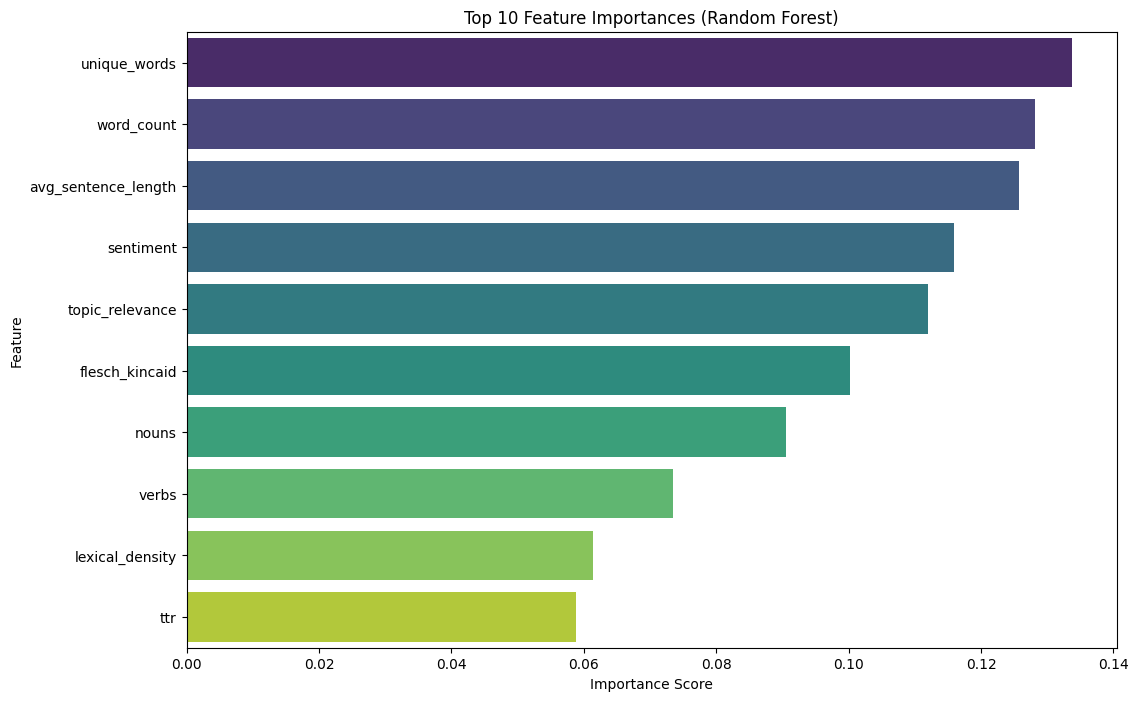

In [ ]:
# Import libraries
import spacy
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
from textstat import textstat
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sentence_transformers import SentenceTransformer
import matplotlib.pyplot as plt
import seaborn as sns

# Load models
nlp = spacy.load('en_core_web_sm')
sentiment_analyzer = SentimentIntensityAnalyzer()
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Calculate topic relevance using cosine similarity
def calculate_topic_relevance(essay, topic):
    essay_embedding = sbert_model.encode(essay)
    topic_embedding = sbert_model.encode(topic)
    similarity = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )
    return similarity

# Poetic justice detection
def detect_poetic_justice(essay):
    doc = nlp(essay)

    # Justice-related keywords
    justice_keywords = ["deserve", "deserved", "justice", "punished", "rewarded", "consequences", "virtue", "vice"]
    justice_count = sum(1 for token in doc if token.text.lower() in justice_keywords)

    # Sentiment shift (difference between most positive and most negative sentences)
    sentences = list(doc.sents)
    if len(sentences) > 1:
        sentiment_scores = [sentiment_analyzer.polarity_scores(sent.text)['compound'] for sent in sentences]
        sentiment_shift = max(sentiment_scores) - min(sentiment_scores)
    else:
        sentiment_shift = 0

    # Causal phrases
    causal_phrases = ["because", "due to", "as a result"]
    causal_count = sum(1 for token in doc if token.text.lower() in causal_phrases)

    # Calculate poetic justice score
    poetic_justice_score = justice_count + sentiment_shift + causal_count
    return poetic_justice_score

# Feature extraction function
def extract_features_with_topic(essay, topic):
    doc = nlp(essay)

    # Basic text statistics
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0
    ttr = unique_words / word_count if word_count > 0 else 0

    # Part-of-speech counts
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability scores
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Sentiment analysis (VADER)
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']

    # Custom features
    topic_relevance = calculate_topic_relevance(essay, topic)

    # Feature dictionary
    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance
    }

    return features

# Load dataset
df = pd.read_csv('essays.csv')

# Extract features from essays
engineered_features = [
    extract_features_with_topic(essay, topic) 
    for essay, topic in zip(df['Essay Answer'], df['Essay Question'])
]
X = pd.DataFrame(engineered_features)
y = df['Score']

print("\nExtracted Features:")
print(X.head())

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize Random Forest model
rf_model = RandomForestRegressor(n_estimators=200, max_depth=20, random_state=42)

# Train model
print("\nTraining Random Forest model...")
rf_model.fit(X_train, y_train)

# Evaluate model
y_pred = rf_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print("\nModel Evaluation:")
print(f"Test MSE: {mse:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test MAE: {mae:.4f}")

# Save model
import joblib
joblib.dump(rf_model, 'rf_essay_scorer.pkl')
print("\nRandom Forest model saved successfully!")

# Feature importance analysis
feature_importances = rf_model.feature_importances_
importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': feature_importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("\nFeature Importances (Top 10):")
print(importance_df.head(10))

# Visualize feature importance
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='viridis')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()


### ANN with SBERT + EF (Lime for Featrure Ranking)

Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [02:19<00:00, 21.30it/s]



Starting training...
Epoch 5/50, Loss: 276.0037
Epoch 10/50, Loss: 246.4193
Epoch 15/50, Loss: 240.7506
Epoch 20/50, Loss: 234.3209
Epoch 25/50, Loss: 227.8675
Epoch 30/50, Loss: 229.6172
Epoch 35/50, Loss: 233.5655
Epoch 40/50, Loss: 217.7854
Epoch 45/50, Loss: 214.7617
Epoch 50/50, Loss: 216.6730
Test RMSE: 1.7864, MAE: 1.5251

Model saved successfully!

Generating LIME explanations across the test dataset...


100%|██████████| 596/596 [06:47<00:00,  1.46it/s]



Mean Feature Importance (LIME):
noun_count: 0.0319
lexical_density: 0.0309
ttr: -0.0160
topic_relevance: -0.0098
word_count: -0.0074
unique_words: -0.0037
verb_count: -0.0026
flesch_kincaid: 0.0017
avg_sentence_length: -0.0008


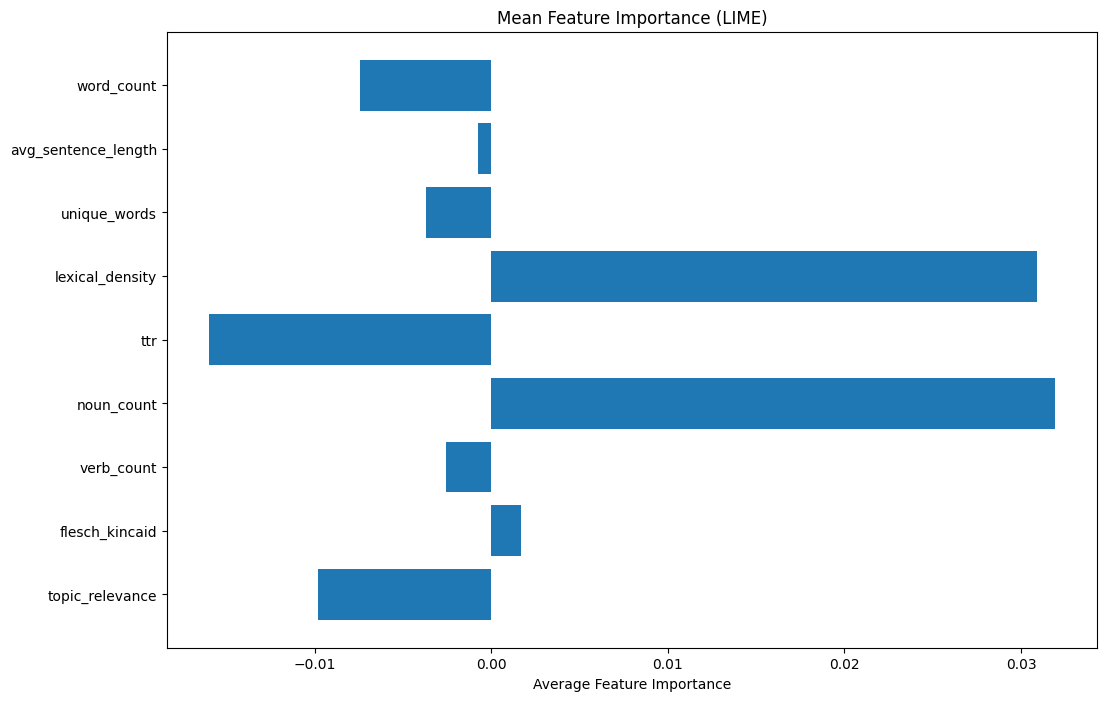

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Feature extraction function
def extract_features(essay: str, topic: str) -> np.ndarray:
    """
    Extract linguistic, grammatical, and semantic features from the essay.
    """
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar (Nouns and Verbs count)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Topic Relevance (Cosine Similarity using SBERT)
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density, 
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance
    ]), essay_embedding

# Neural network model
class EssayRegressor(nn.Module):
    def __init__(self, input_dim: int):
        super(EssayRegressor, self).__init__()
        
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)

# Data preparation
def prepare_data(csv_path: str):
    """
    Prepare data by combining SBERT embeddings and engineered features.
    """
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)

    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        engineered_features, essay_embedding = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))

    X = np.array(combined_features)
    y = df['Score'].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return map(torch.FloatTensor, (X_train, X_test, y_train.reshape(-1, 1), y_test.reshape(-1, 1)))

# Model training function
def train_model(model, X_train, y_train, X_test, y_test, num_epochs=50, batch_size=32, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    print("\nStarting training...")
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for i in range(0, len(X_train), batch_size):
            batch_X = X_train[i:i + batch_size]
            batch_y = y_train[i:i + batch_size]
            
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
        
        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss:.4f}")
    
    # Evaluate model
    model.eval()
    with torch.no_grad():
        preds = model(X_test)
        mse = mean_squared_error(y_test.numpy(), preds.numpy())
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(y_test.numpy(), preds.numpy())
        print(f"Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")

    return model

# LIME explanation function
def explain_with_lime(model, X_test, feature_names):
    model.eval()

    def predict_fn(x):
        x_tensor = torch.FloatTensor(x)
        with torch.no_grad():
            return model(x_tensor).numpy()

    num_sbert_dims = 384  # SBERT embedding size
    engineered_feature_names = feature_names[num_sbert_dims:]

    explainer = LimeTabularExplainer(
        training_data=X_test.numpy(),
        mode="regression",
        feature_names=feature_names,
        discretize_continuous=True,
        sample_around_instance=True
    )

    feature_weights = {feature: [] for feature in engineered_feature_names}

    print("\nGenerating LIME explanations across the test dataset...")
    for sample in tqdm(X_test.numpy()):
        exp = explainer.explain_instance(sample, predict_fn, num_features=len(engineered_feature_names))
        
        for idx, weight in exp.as_map()[1]:
            if idx >= num_sbert_dims:
                feature_name = engineered_feature_names[idx - num_sbert_dims]
                feature_weights[feature_name].append(weight)

    # Average importance across all samples
    avg_importance = {feature: np.mean(weights) for feature, weights in feature_weights.items()}

    print("\nMean Feature Importance (LIME):")
    for feature, importance in sorted(avg_importance.items(), key=lambda x: abs(x[1]), reverse=True):
        print(f"{feature}: {importance:.4f}")

    # Plotting feature importance
    plt.figure(figsize=(12, 8))
    plt.barh(list(avg_importance.keys()), list(avg_importance.values()))
    plt.xlabel("Average Feature Importance")
    plt.title("Mean Feature Importance (LIME)")
    plt.gca().invert_yaxis()
    plt.show()

# Main function
def main():
    torch.manual_seed(42)
    np.random.seed(42)

    csv_path = 'essays.csv'
    X_train, X_test, y_train, y_test = prepare_data(csv_path)
    
    input_dim = X_train.shape[1]
    model = EssayRegressor(input_dim=input_dim)
    
    model = train_model(model, X_train, y_train, X_test, y_test)

    torch.save(model.state_dict(), 'essay_scoring_model_sbert.pth')
    print("\nModel saved successfully!")

    feature_names = [f"SBERT_{i}" for i in range(384)] + [
        "word_count", "avg_sentence_length", "unique_words", "lexical_density",
        "ttr", "noun_count", "verb_count", "flesch_kincaid", "topic_relevance"
    ]

    explain_with_lime(model, X_test, feature_names)

if __name__ == "__main__":
    main()

### Random Forest with GloVe embeddings and EF

In [ ]:
import numpy as np
import pandas as pd
import torch
import os
import math
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
import joblib

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

class GloVeEmbeddings:
    def __init__(self, embedding_dim=300, glove_path=None):
        """
        Initialize GloVeEmbeddings with embedding dimension and path to the GloVe file.
        """
        self.embedding_dim = embedding_dim
        self.word_to_vec = {}
        self.glove_path = glove_path

    def load_embeddings(self):
        """
        Load GloVe embeddings into memory from the specified path.
        """
        print(f"Loading {self.embedding_dim}-dimensional GloVe embeddings from {self.glove_path}...")

        if not os.path.exists(self.glove_path):
            raise FileNotFoundError(f"GloVe file not found at {self.glove_path}. Please check the path.")

        with open(self.glove_path, 'r', encoding='utf-8') as f:
            for line in tqdm(f, desc="Loading embeddings"):
                values = line.split()
                word = values[0]
                vector = np.asarray(values[1:], dtype='float32')
                self.word_to_vec[word] = vector

        print(f"Loaded {len(self.word_to_vec)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        """
        Retrieve the embedding for a given word. Returns a zero vector if the word is not found.
        """
        return self.word_to_vec.get(word.lower(), np.zeros(self.embedding_dim))

    def get_text_embedding(self, text: str) -> np.ndarray:
        """
        Compute the average embedding for a given piece of text.
        """
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words]

        if not word_embeddings:
            return np.zeros(self.embedding_dim)

        return np.mean(word_embeddings, axis=0)


def extract_features(essay: str, topic: str) -> np.ndarray:
    """
    Extract linguistic, grammatical, and semantic features from the essay
    """
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar (Nouns and Verbs count)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Topic Relevance (Cosine Similarity using SBERT)
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density, 
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance
    ])


def prepare_data(csv_path: str, glove: GloVeEmbeddings):
    """
    Prepare data by combining GloVe embeddings and engineered features
    """
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)
    
    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        essay_embedding = glove.get_text_embedding(essay)
        engineered_features = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))
    
    X = np.array(combined_features)
    y = df['Score'].values

    print(f"Shape of combined features (X): {X.shape}")
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test


def train_rf_model(X_train, y_train, X_test, y_test, n_estimators=200, max_depth=20):
    """
    Train a Random Forest model on essay features and evaluate performance.
    """
    print("\nTraining Random Forest model...")

    # Initialize and train Random Forest model
    rf_model = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)

    # Evaluate model performance
    preds = rf_model.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)

    print(f"Random Forest Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")
    return rf_model


def main():
    # Set random seeds for reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    # Path to GloVe embeddings (ensure you have this file locally)
    glove_path = '/Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt'

    # Initialize and load GloVe embeddings
    glove = GloVeEmbeddings(embedding_dim=300, glove_path=glove_path)
    glove.load_embeddings()

    # Prepare the dataset
    csv_path = 'essays.csv'
    X_train, X_test, y_train, y_test = prepare_data(csv_path, glove)

    # Train and evaluate Random Forest model
    rf_model = train_rf_model(X_train, y_train, X_test, y_test)

    # Save the trained Random Forest model
    model_path = 'essay_scoring_rf_model.pkl'
    joblib.dump(rf_model, model_path)
    print(f"\nRandom Forest model saved successfully to {model_path}!")


if __name__ == "__main__":
    main()

Loading 300-dimensional GloVe embeddings from /Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt...


Loading embeddings: 400000it [00:13, 29658.54it/s]


Loaded 400000 word vectors.
Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [02:34<00:00, 19.33it/s]


Shape of combined features (X): (2979, 309)

Training Random Forest model...
Random Forest Test RMSE: 1.7217, MAE: 1.4179

Random Forest model saved successfully to essay_scoring_rf_model.pkl!


### XGB with Engineered Features

In [ ]:
import spacy
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
from textstat import textstat
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sentence_transformers import SentenceTransformer
import xgboost as xgb
import joblib

# Load models
nlp = spacy.load('en_core_web_sm')
sentiment_analyzer = SentimentIntensityAnalyzer()
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Helper functions for feature extraction
def calculate_topic_relevance(essay, topic):
    essay_embedding = sbert_model.encode(essay)
    topic_embedding = sbert_model.encode(topic)
    similarity = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )
    return similarity
    

def extract_features_with_topic(essay, topic):
    doc = nlp(essay)

    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0
    ttr = unique_words / word_count if word_count > 0 else 0
    
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}
    
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)
    dale_chall = textstat.dale_chall_readability_score(essay)
    
    sentiment_scores = sentiment_analyzer.polarity_scores(essay)
    sentiment = sentiment_scores['compound']
    
    sentences = [sent.text for sent in doc.sents]
    if len(sentences) > 1:
        embeddings = sbert_model.encode(sentences)
        coherence = np.mean([
            np.dot(embeddings[i], embeddings[i + 1]) /
            (np.linalg.norm(embeddings[i]) * np.linalg.norm(embeddings[i + 1]))
            for i in range(len(embeddings) - 1)
        ])
    else:
        coherence = 0

    topic_relevance = calculate_topic_relevance(essay, topic)

    features = {
        'word_count': word_count,
        'avg_sentence_length': avg_sentence_length,
        'unique_words': unique_words,
        'lexical_density': lexical_density,
        'ttr': ttr,
        'nouns': pos_count['NOUN'],
        'verbs': pos_count['VERB'],
        'flesch_kincaid': flesch_kincaid,
        'sentiment': sentiment,
        'topic_relevance': topic_relevance
    }

    return features

# Load and prepare data
df = pd.read_csv('essays.csv')

# Extract features
engineered_features = [
    extract_features_with_topic(essay, topic) 
    for essay, topic in zip(df['Essay Answer'], df['Essay Question'])
]
X = pd.DataFrame(engineered_features)
y = df['Score']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# XGBoost Model
xgb_model = xgb.XGBRegressor(
    objective='reg:squarederror',
    n_estimators=300,
    max_depth=7,
    learning_rate=0.01,
    colsample_bytree=0.8,
    subsample=0.8,
    random_state=42
)

# Train the XGB model
print("\nTraining XGBoost model...")
xgb_model.fit(X_train, y_train)

# Evaluate the model
y_pred = xgb_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f"\nTest Metrics:")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

# Save the XGBoost model
joblib.dump(xgb_model, 'xgb_essay_scorer_without_zeros.pkl')
print("\nXGBoost Model saved successfully!")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/huggingface_hub/file_download.py:1142: FutureWarning:


Training XGBoost model...

Test Metrics:
MSE: 3.0747
RMSE: 1.7535
MAE: 1.4417

XGBoost Model saved successfully!


### XGB with GloVe Embeddings and EF

In [ ]:
import numpy as np
import pandas as pd
import torch
import os
import math
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
import joblib
import xgboost as xgb

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

class GloVeEmbeddings:
    def __init__(self, embedding_dim=300, glove_path=None):
        """
        Initialize GloVeEmbeddings with embedding dimension and path to the GloVe file.
        """
        self.embedding_dim = embedding_dim
        self.word_to_vec = {}
        self.glove_path = glove_path

    def load_embeddings(self):
        """
        Load GloVe embeddings into memory from the specified path.
        """
        print(f"Loading {self.embedding_dim}-dimensional GloVe embeddings from {self.glove_path}...")

        if not os.path.exists(self.glove_path):
            raise FileNotFoundError(f"GloVe file not found at {self.glove_path}. Please check the path.")

        with open(self.glove_path, 'r', encoding='utf-8') as f:
            for line in tqdm(f, desc="Loading embeddings"):
                values = line.split()
                word = values[0]
                vector = np.asarray(values[1:], dtype='float32')
                self.word_to_vec[word] = vector

        print(f"Loaded {len(self.word_to_vec)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        """
        Retrieve the embedding for a given word. Returns a zero vector if the word is not found.
        """
        return self.word_to_vec.get(word.lower(), np.zeros(self.embedding_dim))

    def get_text_embedding(self, text: str) -> np.ndarray:
        """
        Compute the average embedding for a given piece of text.
        """
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words]

        if not word_embeddings:
            return np.zeros(self.embedding_dim)

        return np.mean(word_embeddings, axis=0)


def extract_features(essay: str, topic: str) -> np.ndarray:
    """
    Extract linguistic, grammatical, and semantic features from the essay
    """
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar (Nouns and Verbs count)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Topic Relevance (Cosine Similarity using SBERT)
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density,
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance
    ])


def prepare_data(csv_path: str, glove: GloVeEmbeddings):
    """
    Prepare data by combining GloVe embeddings and engineered features
    """
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)
    
    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        essay_embedding = glove.get_text_embedding(essay)
        engineered_features = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))
    
    X = np.array(combined_features)
    y = df['Score'].values

    print(f"Shape of combined features (X): {X.shape}")
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test


def train_xgb_model(X_train, y_train, X_test, y_test):
    """
    Train an XGBoost model on essay features and evaluate performance.
    """
    print("\nTraining XGBoost model...")

    # Initialize XGBoost model with hyperparameters
    xgb_model = xgb.XGBRegressor(
        objective='reg:squarederror',
        n_estimators=300,
        max_depth=10,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    # Train the model
    xgb_model.fit(X_train, y_train)

    # Evaluate model performance
    preds = xgb_model.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)

    print(f"XGBoost Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")
    return xgb_model


def main():
    # Set random seeds for reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    # Path to GloVe embeddings (ensure you have this file locally)
    glove_path = '/Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt'

    # Initialize and load GloVe embeddings
    glove = GloVeEmbeddings(embedding_dim=300, glove_path=glove_path)
    glove.load_embeddings()

    # Prepare the dataset
    csv_path = 'essays.csv'
    X_train, X_test, y_train, y_test = prepare_data(csv_path, glove)

    # Train and evaluate XGBoost model
    xgb_model = train_xgb_model(X_train, y_train, X_test, y_test)

    # Save the trained XGBoost model
    model_path = 'essay_scoring_xgb_model.pkl'
    joblib.dump(xgb_model, model_path)
    print(f"\nXGBoost model saved successfully to {model_path}!")


if __name__ == "__main__":
    main()

Loading 300-dimensional GloVe embeddings from /Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt...


Loading embeddings: 400000it [00:13, 30555.88it/s]


Loaded 400000 word vectors.
Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [02:35<00:00, 19.18it/s]


Shape of combined features (X): (2979, 309)

Training XGBoost model...
XGBoost Test RMSE: 1.7563, MAE: 1.4389

XGBoost model saved successfully to essay_scoring_xgb_model.pkl!


### RF with GloVe + EF with Errors and MinMaxScalar

In [ ]:
import numpy as np
import pandas as pd
import torch
import os
import math
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import joblib
from spellchecker import SpellChecker
import language_tool_python

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Initialize SpellChecker and LanguageTool
spell = SpellChecker()
grammar_tool = language_tool_python.LanguageTool('en-US')


class GloVeEmbeddings:
    def __init__(self, embedding_dim=300, glove_path=None):
        """
        Initialize GloVeEmbeddings with embedding dimension and path to the GloVe file.
        """
        self.embedding_dim = embedding_dim
        self.word_to_vec = {}
        self.glove_path = glove_path

    def load_embeddings(self):
        """
        Load GloVe embeddings into memory from the specified path.
        """
        print(f"Loading {self.embedding_dim}-dimensional GloVe embeddings from {self.glove_path}...")

        if not os.path.exists(self.glove_path):
            raise FileNotFoundError(f"GloVe file not found at {self.glove_path}. Please check the path.")

        with open(self.glove_path, 'r', encoding='utf-8') as f:
            for line in tqdm(f, desc="Loading embeddings"):
                values = line.split()
                word = values[0]
                vector = np.asarray(values[1:], dtype='float32')
                self.word_to_vec[word] = vector

        print(f"Loaded {len(self.word_to_vec)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        """
        Retrieve the embedding for a given word. Returns a zero vector if the word is not found.
        """
        return self.word_to_vec.get(word.lower(), np.zeros(self.embedding_dim))

    def get_text_embedding(self, text: str) -> np.ndarray:
        """
        Compute the average embedding for a given piece of text.
        """
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words]

        if not word_embeddings:
            return np.zeros(self.embedding_dim)

        return np.mean(word_embeddings, axis=0)


def extract_features(essay: str, topic: str) -> np.ndarray:
    """
    Extract linguistic, grammatical, and semantic features from the essay
    """
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar (Nouns and Verbs count)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Topic Relevance (Cosine Similarity using SBERT)
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    # Typo Detection (Rate of Misspelled Words)
    misspelled_words = len(list(spell.unknown(essay.split())))
    typo_rate = misspelled_words / word_count if word_count > 0 else 0

    # Grammar Error Detection (Rate of Grammar Errors)
    grammar_errors = len(grammar_tool.check(essay))
    grammar_error_rate = grammar_errors / word_count if word_count > 0 else 0

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density,
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance, typo_rate, grammar_error_rate
    ])


def prepare_data(csv_path: str, glove: GloVeEmbeddings):
    """
    Prepare data by combining GloVe embeddings and engineered features
    """
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)

    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        essay_embedding = glove.get_text_embedding(essay)
        engineered_features = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))

    X = np.array(combined_features)
    y = df['Score'].values

    print(f"Shape of combined features (X): {X.shape}")

    # Apply Min-Max Scaling to Features
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)

    # Save scaler for future use
    joblib.dump(scaler, 'minmax_scaler.pkl')
    print("MinMax Scaler saved successfully!")

    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test


def train_rf_model(X_train, y_train, X_test, y_test, n_estimators=200, max_depth=20):
    """
    Train a Random Forest model on essay features and evaluate performance.
    """
    print("\nTraining Random Forest model...")

    # Initialize and train Random Forest model
    rf_model = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)

    # Evaluate model performance
    preds = rf_model.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)

    print(f"Random Forest Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")
    return rf_model


def main():
    # Set random seeds for reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    # Path to GloVe embeddings (ensure you have this file locally)
    glove_path = '/Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt'

    # Initialize and load GloVe embeddings
    glove = GloVeEmbeddings(embedding_dim=300, glove_path=glove_path)
    glove.load_embeddings()

    # Prepare the dataset
    csv_path = 'essays.csv'
    X_train, X_test, y_train, y_test = prepare_data(csv_path, glove)

    # Train and evaluate Random Forest model
    rf_model = train_rf_model(X_train, y_train, X_test, y_test)

    # Save the trained Random Forest model
    model_path = 'essay_scoring_rf_model.pkl'
    joblib.dump(rf_model, model_path)
    print(f"\nRandom Forest model saved successfully to {model_path}!")


if __name__ == "__main__":
    main()

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Loading 300-dimensional GloVe embeddings from /Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt...


Loading embeddings: 400000it [00:12, 30860.27it/s]


Loaded 400000 word vectors.
Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [06:44<00:00,  7.36it/s]


Shape of combined features (X): (2979, 311)
MinMax Scaler saved successfully!

Training Random Forest model...
Random Forest Test RMSE: 1.7072, MAE: 1.4049

Random Forest model saved successfully to essay_scoring_rf_model.pkl!


### RF with GloVe + EF with Errors and MinMaxScalar (Shap)

Loading 300-dimensional GloVe embeddings from /Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt...


Loading embeddings: 400000it [00:10, 37331.33it/s]


Loaded 400000 word vectors.
Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [06:43<00:00,  7.38it/s]


Shape of combined features (X): (2979, 311)
MinMax Scaler saved successfully!

Training Random Forest model...
Random Forest Test RMSE: 1.7072, MAE: 1.4049

Random Forest model saved successfully to essay_scoring_rf_model_shap.pkl!


100%|██████████| 2979/2979 [05:35<00:00,  8.89it/s]


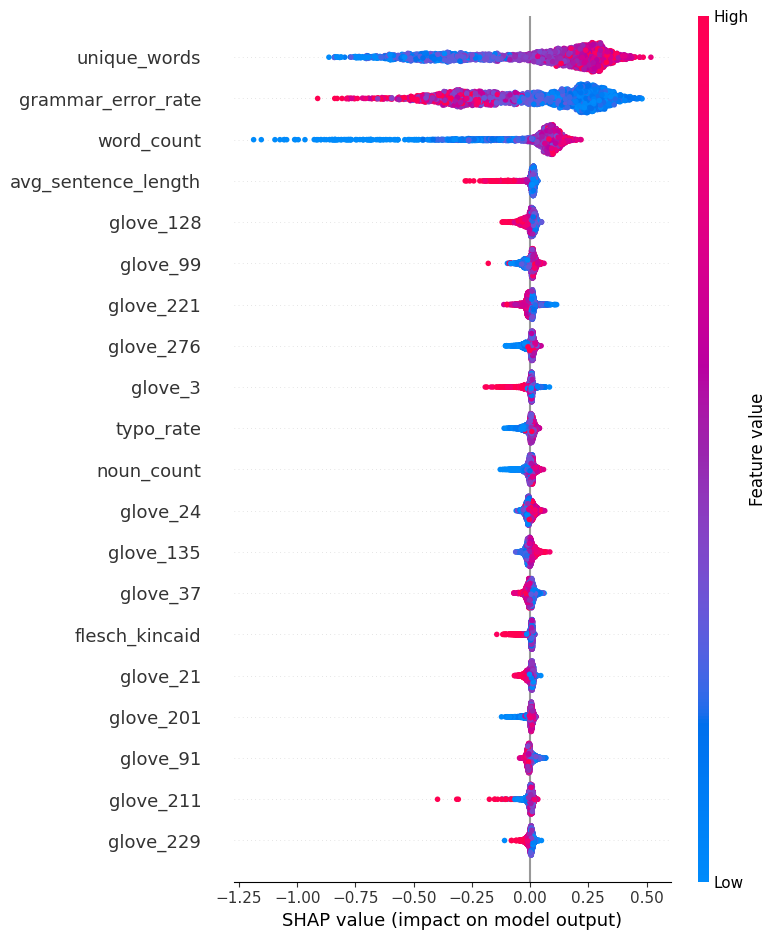

In [ ]:
import numpy as np
import pandas as pd
import torch
import os
import math
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import joblib
from spellchecker import SpellChecker
import language_tool_python
import shap
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Initialize SpellChecker and LanguageTool
spell = SpellChecker()
grammar_tool = language_tool_python.LanguageTool('en-US')


class GloVeEmbeddings:
    def __init__(self, embedding_dim=300, glove_path=None):
        """
        Initialize GloVeEmbeddings with embedding dimension and path to the GloVe file.
        """
        self.embedding_dim = embedding_dim
        self.word_to_vec = {}
        self.glove_path = glove_path

    def load_embeddings(self):
        """
        Load GloVe embeddings into memory from the specified path.
        """
        print(f"Loading {self.embedding_dim}-dimensional GloVe embeddings from {self.glove_path}...")

        if not os.path.exists(self.glove_path):
            raise FileNotFoundError(f"GloVe file not found at {self.glove_path}. Please check the path.")

        with open(self.glove_path, 'r', encoding='utf-8') as f:
            for line in tqdm(f, desc="Loading embeddings"):
                values = line.split()
                word = values[0]
                vector = np.asarray(values[1:], dtype='float32')
                self.word_to_vec[word] = vector

        print(f"Loaded {len(self.word_to_vec)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        """
        Retrieve the embedding for a given word. Returns a zero vector if the word is not found.
        """
        return self.word_to_vec.get(word.lower(), np.zeros(self.embedding_dim))

    def get_text_embedding(self, text: str) -> np.ndarray:
        """
        Compute the average embedding for a given piece of text.
        """
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words]

        if not word_embeddings:
            return np.zeros(self.embedding_dim)

        return np.mean(word_embeddings, axis=0)


def extract_features(essay: str, topic: str) -> np.ndarray:
    """
    Extract linguistic, grammatical, and semantic features from the essay
    """
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar (Nouns and Verbs count)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Topic Relevance (Cosine Similarity using SBERT)
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    # Typo Detection (Rate of Misspelled Words)
    misspelled_words = len(list(spell.unknown(essay.split())))
    typo_rate = misspelled_words / word_count if word_count > 0 else 0

    # Grammar Error Detection (Rate of Grammar Errors)
    grammar_errors = len(grammar_tool.check(essay))
    grammar_error_rate = grammar_errors / word_count if word_count > 0 else 0

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density,
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance, typo_rate, grammar_error_rate
    ])


def prepare_data(csv_path: str, glove: GloVeEmbeddings):
    """
    Prepare data by combining GloVe embeddings and engineered features
    """
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)

    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        essay_embedding = glove.get_text_embedding(essay)
        engineered_features = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))

    X = np.array(combined_features)
    y = df['Score'].values

    print(f"Shape of combined features (X): {X.shape}")

    # Apply Min-Max Scaling to Features
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)

    # Save scaler for future use
    joblib.dump(scaler, 'minmax_scaler_shap.pkl')
    print("MinMax Scaler saved successfully!")

    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test


def train_rf_model(X_train, y_train, X_test, y_test, n_estimators=200, max_depth=20):
    """
    Train a Random Forest model on essay features and evaluate performance.
    """
    print("\nTraining Random Forest model...")

    # Initialize and train Random Forest model
    rf_model = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)

    # Evaluate model performance
    preds = rf_model.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)

    print(f"Random Forest Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")
    return rf_model


def main():
    # Set random seeds for reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    # Path to GloVe embeddings (ensure you have this file locally)
    glove_path = '/Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt'

    # Initialize and load GloVe embeddings
    glove = GloVeEmbeddings(embedding_dim=300, glove_path=glove_path)
    glove.load_embeddings()

    # Prepare the dataset
    csv_path = 'essays.csv'
    X_train, X_test, y_train, y_test = prepare_data(csv_path, glove)

    # Train and evaluate Random Forest model
    rf_model = train_rf_model(X_train, y_train, X_test, y_test)

    # Save the trained Random Forest model
    model_path = 'essay_scoring_rf_model_shap.pkl'
    joblib.dump(rf_model, model_path)
    print(f"\nRandom Forest model saved successfully to {model_path}!")

    # Load model and scaler
    rf_model = joblib.load('essay_scoring_rf_model_shap.pkl')
    scaler = joblib.load('minmax_scaler_shap.pkl')

    # Get feature names
    glove_feature_names = [f"glove_{i}" for i in range(300)]
    engineered_names = [
        "word_count", "avg_sentence_length", "unique_words", "lexical_density",
        "ttr", "noun_count", "verb_count", "flesch_kincaid", 
        "topic_relevance", "typo_rate", "grammar_error_rate"
    ]
    feature_names = glove_feature_names + engineered_names

    # Recalculate full dataset features
    df = pd.read_csv('essays.csv')

    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), total=len(df)):
        essay_embedding = glove.get_text_embedding(essay)
        engineered_features = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))

    X = np.array(combined_features)
    X_scaled = scaler.transform(X)

    # Create SHAP explainer
    explainer = shap.TreeExplainer(rf_model)
    shap_values = explainer.shap_values(X_scaled)

    # Summary plot
    shap.summary_plot(shap_values, X_scaled, feature_names=feature_names)


if __name__ == "__main__":
    main()

### Paired t-test for Random Forest with GloVe embeddings and Engineered Features (with 2 penalty features and ANN with SBERT embeddings and engineered features

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer
from lime.lime_tabular import LimeTabularExplainer
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Feature extraction function
def extract_features(essay: str, topic: str) -> np.ndarray:
    doc = nlp(essay)

    # Basic Stats
    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0

    # Vocabulary Richness
    ttr = unique_words / word_count if word_count > 0 else 0

    # Grammar (Nouns and Verbs count)
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}

    # Readability
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    # Topic Relevance (Cosine Similarity using SBERT)
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density, 
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance
    ]), essay_embedding

# Neural network model
class EssayRegressor(nn.Module):
    def __init__(self, input_dim: int):
        super(EssayRegressor, self).__init__()
        
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)

# Data preparation
def prepare_data(csv_path: str):
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)

    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        engineered_features, essay_embedding = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))

    X = np.array(combined_features)
    y = df['Score'].values

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return map(torch.FloatTensor, (X_train, X_test, y_train.reshape(-1, 1), y_test.reshape(-1, 1)))

# Paired t-test function
def perform_paired_ttest(y_true, y_pred):
    y_true_np = y_true.numpy().flatten()
    y_pred_np = y_pred.numpy().flatten()
    
    t_stat, p_value = ttest_rel(y_true_np, y_pred_np)
    
    print("\nPaired t-test Results:")
    print(f"T-statistic: {t_stat:.4f}")
    print(f"P-value: {p_value:.4f}")
    
    if p_value < 0.05:
        print("→ The difference between actual and predicted scores is statistically significant.")
    else:
        print("→ No statistically significant difference between actual and predicted scores.")

# Model training function
def train_model(model, X_train, y_train, X_test, y_test, num_epochs=50, batch_size=32, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    print("\nStarting training...")
    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        
        for i in range(0, len(X_train), batch_size):
            batch_X = X_train[i:i + batch_size]
            batch_y = y_train[i:i + batch_size]
            
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
        
        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss:.4f}")
    
    # Evaluate model
    model.eval()
    with torch.no_grad():
        preds = model(X_test)
        mse = mean_squared_error(y_test.numpy(), preds.numpy())
        rmse = math.sqrt(mse)
        mae = mean_absolute_error(y_test.numpy(), preds.numpy())
        print(f"\nTest RMSE: {rmse:.4f}, MAE: {mae:.4f}")

        # Paired t-test
        perform_paired_ttest(y_test, preds)

    return model

# LIME explanation function
def explain_with_lime(model, X_test, feature_names):
    model.eval()

    def predict_fn(x):
        x_tensor = torch.FloatTensor(x)
        with torch.no_grad():
            return model(x_tensor).numpy()

    num_sbert_dims = 384  # SBERT embedding size
    engineered_feature_names = feature_names[num_sbert_dims:]

    explainer = LimeTabularExplainer(
        training_data=X_test.numpy(),
        mode="regression",
        feature_names=feature_names,
        discretize_continuous=True,
        sample_around_instance=True
    )

    feature_weights = {feature: [] for feature in engineered_feature_names}

# Main function
def main():
    torch.manual_seed(42)
    np.random.seed(42)

    csv_path = 'essays.csv'
    X_train, X_test, y_train, y_test = prepare_data(csv_path)
    
    input_dim = X_train.shape[1]
    model = EssayRegressor(input_dim=input_dim)
    
    model = train_model(model, X_train, y_train, X_test, y_test)

    torch.save(model.state_dict(), 'essay_scoring_model_sbert.pth')
    print("\nModel saved successfully!")

    feature_names = [f"SBERT_{i}" for i in range(384)] + [
        "word_count", "avg_sentence_length", "unique_words", "lexical_density",
        "ttr", "noun_count", "verb_count", "flesch_kincaid", "topic_relevance"
    ]

    explain_with_lime(model, X_test, feature_names)

if __name__ == "__main__":
    main()


Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [02:00<00:00, 24.65it/s]



Starting training...
Epoch 5/50, Loss: 276.0037
Epoch 10/50, Loss: 246.4193
Epoch 15/50, Loss: 240.7506
Epoch 20/50, Loss: 234.3209
Epoch 25/50, Loss: 227.8675
Epoch 30/50, Loss: 229.6172
Epoch 35/50, Loss: 233.5655
Epoch 40/50, Loss: 217.7854
Epoch 45/50, Loss: 214.7617
Epoch 50/50, Loss: 216.6730

Test RMSE: 1.7864, MAE: 1.5251

Paired t-test Results:
T-statistic: 4.8800
P-value: 0.0000
→ The difference between actual and predicted scores is statistically significant.

Model saved successfully!


### Wilcoxon test for Random Forest with GloVe embeddings and Engineered Features (with 2 penalty features

In [ ]:
import numpy as np
import pandas as pd
import torch
import os
import math
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import joblib
from spellchecker import SpellChecker
import language_tool_python
from scipy.stats import ttest_rel, wilcoxon

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Initialize SpellChecker and LanguageTool
spell = SpellChecker()
grammar_tool = language_tool_python.LanguageTool('en-US')


class GloVeEmbeddings:
    def __init__(self, embedding_dim=300, glove_path=None):
        self.embedding_dim = embedding_dim
        self.word_to_vec = {}
        self.glove_path = glove_path

    def load_embeddings(self):
        print(f"Loading {self.embedding_dim}-dimensional GloVe embeddings from {self.glove_path}...")
        if not os.path.exists(self.glove_path):
            raise FileNotFoundError(f"GloVe file not found at {self.glove_path}. Please check the path.")
        with open(self.glove_path, 'r', encoding='utf-8') as f:
            for line in tqdm(f, desc="Loading embeddings"):
                values = line.split()
                word = values[0]
                vector = np.asarray(values[1:], dtype='float32')
                self.word_to_vec[word] = vector
        print(f"Loaded {len(self.word_to_vec)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        return self.word_to_vec.get(word.lower(), np.zeros(self.embedding_dim))

    def get_text_embedding(self, text: str) -> np.ndarray:
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words]
        if not word_embeddings:
            return np.zeros(self.embedding_dim)
        return np.mean(word_embeddings, axis=0)


def extract_features(essay: str, topic: str) -> np.ndarray:
    doc = nlp(essay)

    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0
    ttr = unique_words / word_count if word_count > 0 else 0

    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)

    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )

    misspelled_words = len(list(spell.unknown(essay.split())))
    typo_rate = misspelled_words / word_count if word_count > 0 else 0

    grammar_errors = len(grammar_tool.check(essay))
    grammar_error_rate = grammar_errors / word_count if word_count > 0 else 0

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density,
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance, typo_rate, grammar_error_rate
    ])


def prepare_data(csv_path: str, glove: GloVeEmbeddings):
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)

    combined_features = []
    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        essay_embedding = glove.get_text_embedding(essay)
        engineered_features = extract_features(essay, topic)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))

    X = np.array(combined_features)
    y = df['Score'].values

    print(f"Shape of combined features (X): {X.shape}")

    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)
    joblib.dump(scaler, 'minmax_scaler.pkl')
    print("MinMax Scaler saved successfully!")

    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test


def train_rf_model(X_train, y_train):
    print("\nTraining Random Forest model...")
    rf_model = RandomForestRegressor(n_estimators=200, max_depth=20, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)
    return rf_model


def evaluate_model(model, X_test, y_test):
    preds = model.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)

    print(f"\n📊 Evaluation Metrics:")
    print(f"Test RMSE: {rmse:.4f}")
    print(f"Test MAE: {mae:.4f}")

    # Paired T-Test
    t_stat, t_p = ttest_rel(y_test, preds)
    print("\n📌 Paired T-Test:")
    print(f"T-statistic: {t_stat:.4f}")
    print(f"P-value: {t_p:.4f}")
    if t_p < 0.05:
        print("→ The difference is statistically significant.")
    else:
        print("→ The difference is NOT statistically significant.")

    # Wilcoxon Signed-Rank Test
    try:
        w_stat, w_p = wilcoxon(y_test - preds)
        print("\n📌 Wilcoxon Signed-Rank Test:")
        print(f"Statistic: {w_stat:.4f}")
        print(f"P-value: {w_p:.4f}")
        if w_p < 0.05:
            print("→ The difference is statistically significant.")
        else:
            print("→ The difference is NOT statistically significant.")
    except ValueError as e:
        print(f"\n⚠️ Wilcoxon Test Error: {e} (Maybe zero differences or too few non-zero samples?)")

    return preds


def main():
    torch.manual_seed(42)
    np.random.seed(42)

    glove_path = '/Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt'
    csv_path = 'essays.csv'

    glove = GloVeEmbeddings(embedding_dim=300, glove_path=glove_path)
    glove.load_embeddings()

    X_train, X_test, y_train, y_test = prepare_data(csv_path, glove)
    rf_model = train_rf_model(X_train, y_train)

    preds = evaluate_model(rf_model, X_test, y_test)

    joblib.dump(rf_model, 'essay_scoring_rf_model.pkl')
    print("\n✅ Random Forest model saved successfully!")


if __name__ == "__main__":
    main()


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 

Loading 300-dimensional GloVe embeddings from /Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt...


Loading embeddings: 400000it [00:12, 31023.60it/s]


Loaded 400000 word vectors.
Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [05:45<00:00,  8.62it/s]


Shape of combined features (X): (2979, 311)
MinMax Scaler saved successfully!

Training Random Forest model...

📊 Evaluation Metrics:
Test RMSE: 1.7072
Test MAE: 1.4049

📌 Paired T-Test:
T-statistic: -0.1396
P-value: 0.8890
→ The difference is NOT statistically significant.

📌 Wilcoxon Signed-Rank Test:
Statistic: 84388.5000
P-value: 0.2778
→ The difference is NOT statistically significant.

✅ Random Forest model saved successfully!


### RF with GloVe + EF with Errors and MinMaxScalar (Feature Ranking)

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The 

Loading 300-dimensional GloVe embeddings from /Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt...


Loading embeddings: 400000it [00:12, 32890.18it/s]


Loaded 400000 word vectors.
Loading and preparing data...


Processing essays: 100%|██████████| 2979/2979 [05:54<00:00,  8.41it/s]


Shape of combined features (X): (2979, 311)
MinMax Scaler saved successfully!

Training Random Forest model...
Random Forest Test RMSE: 1.7072, MAE: 1.4049

Random Forest model saved successfully to essay_scoring_rf_model_final.pkl!

Feature Importances (Top 10):
                 Feature  Importance
302         unique_words    0.062211
310   grammar_error_rate    0.044152
300           word_count    0.043054
301  avg_sentence_length    0.007487
99              GloVe_99    0.005860
3                GloVe_3    0.005703
211            GloVe_211    0.005646
305           noun_count    0.005448
128            GloVe_128    0.005381
276            GloVe_276    0.005128


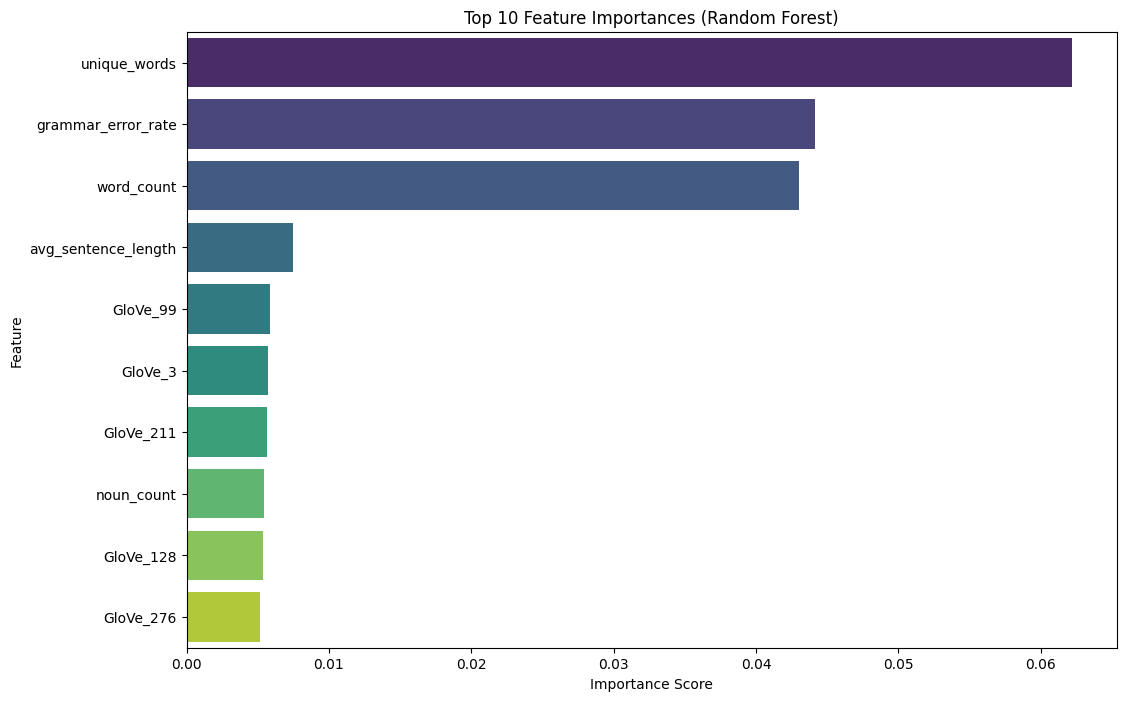

In [ ]:
import numpy as np
import pandas as pd
import torch
import os
import math
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Dict
from tqdm import tqdm
import warnings
import spacy
import textstat
from sentence_transformers import SentenceTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import joblib
from spellchecker import SpellChecker
import language_tool_python

warnings.filterwarnings('ignore')

# Load NLP models
nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Initialize SpellChecker and LanguageTool
spell = SpellChecker()
grammar_tool = language_tool_python.LanguageTool('en-US')


class GloVeEmbeddings:
    def __init__(self, embedding_dim=300, glove_path=None):
        self.embedding_dim = embedding_dim
        self.word_to_vec = {}
        self.glove_path = glove_path

    def load_embeddings(self):
        print(f"Loading {self.embedding_dim}-dimensional GloVe embeddings from {self.glove_path}...")
        if not os.path.exists(self.glove_path):
            raise FileNotFoundError(f"GloVe file not found at {self.glove_path}")
        with open(self.glove_path, 'r', encoding='utf-8') as f:
            for line in tqdm(f, desc="Loading embeddings"):
                values = line.split()
                word = values[0]
                vector = np.asarray(values[1:], dtype='float32')
                self.word_to_vec[word] = vector
        print(f"Loaded {len(self.word_to_vec)} word vectors.")

    def get_word_embedding(self, word: str) -> np.ndarray:
        return self.word_to_vec.get(word.lower(), np.zeros(self.embedding_dim))

    def get_text_embedding(self, text: str) -> np.ndarray:
        words = text.lower().split()
        word_embeddings = [self.get_word_embedding(word) for word in words]
        if not word_embeddings:
            return np.zeros(self.embedding_dim)
        return np.mean(word_embeddings, axis=0)


def extract_features(essay: str, topic: str) -> np.ndarray:
    doc = nlp(essay)

    word_count = len([token.text for token in doc if token.is_alpha])
    sentence_count = len(list(doc.sents))
    avg_sentence_length = word_count / sentence_count if sentence_count > 0 else 0
    unique_words = len(set(token.text.lower() for token in doc if token.is_alpha))
    lexical_density = unique_words / word_count if word_count > 0 else 0
    ttr = unique_words / word_count if word_count > 0 else 0
    pos_count = {pos: len([token for token in doc if token.pos_ == pos]) for pos in ['NOUN', 'VERB']}
    flesch_kincaid = textstat.flesch_kincaid_grade(essay)
    essay_embedding = sbert_model.encode([essay])[0]
    topic_embedding = sbert_model.encode([topic])[0]
    topic_relevance = np.dot(essay_embedding, topic_embedding) / (
        np.linalg.norm(essay_embedding) * np.linalg.norm(topic_embedding)
    )
    misspelled_words = len(list(spell.unknown(essay.split())))
    typo_rate = misspelled_words / word_count if word_count > 0 else 0
    grammar_errors = len(grammar_tool.check(essay))
    grammar_error_rate = grammar_errors / word_count if word_count > 0 else 0

    return np.array([
        word_count, avg_sentence_length, unique_words, lexical_density,
        ttr, pos_count.get('NOUN', 0), pos_count.get('VERB', 0),
        flesch_kincaid, topic_relevance, typo_rate, grammar_error_rate
    ])


def prepare_data(csv_path: str, glove: GloVeEmbeddings):
    print("Loading and preparing data...")
    df = pd.read_csv(csv_path)

    combined_features = []
    engineered_features_list = []

    for essay, topic in tqdm(zip(df['Essay Answer'], df['Essay Question']), desc="Processing essays", total=len(df)):
        essay_embedding = glove.get_text_embedding(essay)
        engineered_features = extract_features(essay, topic)
        engineered_features_list.append(engineered_features)
        combined_features.append(np.hstack((essay_embedding, engineered_features)))

    X = np.array(combined_features)
    y = df['Score'].values
    S = pd.DataFrame(engineered_features_list, columns=[
        "word_count", "avg_sentence_length", "unique_words", "lexical_density",
        "ttr", "noun_count", "verb_count", "flesch_kincaid", "topic_relevance",
        "typo_rate", "grammar_error_rate"
    ])

    print(f"Shape of combined features (X): {X.shape}")

    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)
    joblib.dump(scaler, 'minmax_scaler_final.pkl')
    print("MinMax Scaler saved successfully!")

    X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test, S, y


def train_rf_model(X_train, y_train, X_test, y_test, n_estimators=200, max_depth=20):
    print("\nTraining Random Forest model...")
    rf_model = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)

    preds = rf_model.predict(X_test)
    mse = mean_squared_error(y_test, preds)
    rmse = math.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)

    print(f"Random Forest Test RMSE: {rmse:.4f}, MAE: {mae:.4f}")
    return rf_model


def main():
    torch.manual_seed(42)
    np.random.seed(42)

    glove_path = '/Users/shivam/Flame Uni/Essay evaluator/test_rl/glove.6B.300d.txt'
    csv_path = 'essays.csv'

    glove = GloVeEmbeddings(embedding_dim=300, glove_path=glove_path)
    glove.load_embeddings()

    X_train, X_test, y_train, y_test, S, y = prepare_data(csv_path, glove)

    rf_model = train_rf_model(X_train, y_train, X_test, y_test)

    joblib.dump(rf_model, 'essay_scoring_rf_model_final.pkl')
    print("\nRandom Forest model saved successfully to essay_scoring_rf_model_final.pkl!")

    feature_importances = rf_model.feature_importances_

    # Generate column names for all features
    glove_features = [f"GloVe_{i}" for i in range(300)]
    engineered_feature_names = S.columns.tolist()
    all_feature_names = glove_features + engineered_feature_names

    # Create DataFrame with correct matching dimensions
    importance_df = pd.DataFrame({
        'Feature': all_feature_names,
        'Importance': feature_importances
    }).sort_values(by='Importance', ascending=False)

    print("\nFeature Importances (Top 10):")
    print(importance_df.head(10))

    plt.figure(figsize=(12, 8))
    sns.barplot(x='Importance', y='Feature', data=importance_df.head(10), palette='viridis')
    plt.title('Top 10 Feature Importances (Random Forest)')
    plt.xlabel('Importance Score')
    plt.ylabel('Feature')
    plt.show()


if __name__ == "__main__":
    main()